# Refining and transporting encoded modules

A finite encoding is the working description of a module. Changing that description means tracking the classifier, the finite poset, and the linear maps together. The same dimensions or the same colored support do not establish an identification.

This guide assumes [spaces and maps](../spaces_and_maps.md) and the [finite-encoding lesson](../finite_encodings.md). You will compare two descriptions of one square, inspect an actual naturality square, and transport a module along an order map. The final example explains why a valid comparison of individual modules does not make finite-category Ext independent of the encoding.

1. Put two encodings on a realized common base.
2. Follow labels and matrices through a comparison.
3. Separate a Kan comparison from a derived-category claim.

The [reference](../src/reference/change_of_posets.md) owns keyword and return contracts. [The implementation account](../implementation/change_of_posets.md) explains the constructions and their costs.


In [1]:
import TamerOp as OP
import CairoMakie
using LinearAlgebra: I

field = OP.CoreModules.QQField()
P = OP.Advanced.ProductOfChainsPoset((3, 3))
R = OP.Advanced.ProductOfChainsPoset((2, 2))


ProductOfChainsPoset
  axes: (2, 2)
  nvertices: 4
  model: finite product of chains

## One square, two finite descriptions

On the nonnegative parameter plane, our module has a one-dimensional space on $[0,2)\times[0,2)$ and zero elsewhere in that domain. Parameters below zero are unrepresented, not inferred zero stalks. The left description subdivides the square at coordinate 1. The right description uses only the boundary at coordinate 2. Internal maps are identities; maps into zero stalks are zero matrices with their actual target-by-source shape.

Constructing a module directly is useful for algebraic examples: no point cloud or filtration is required.


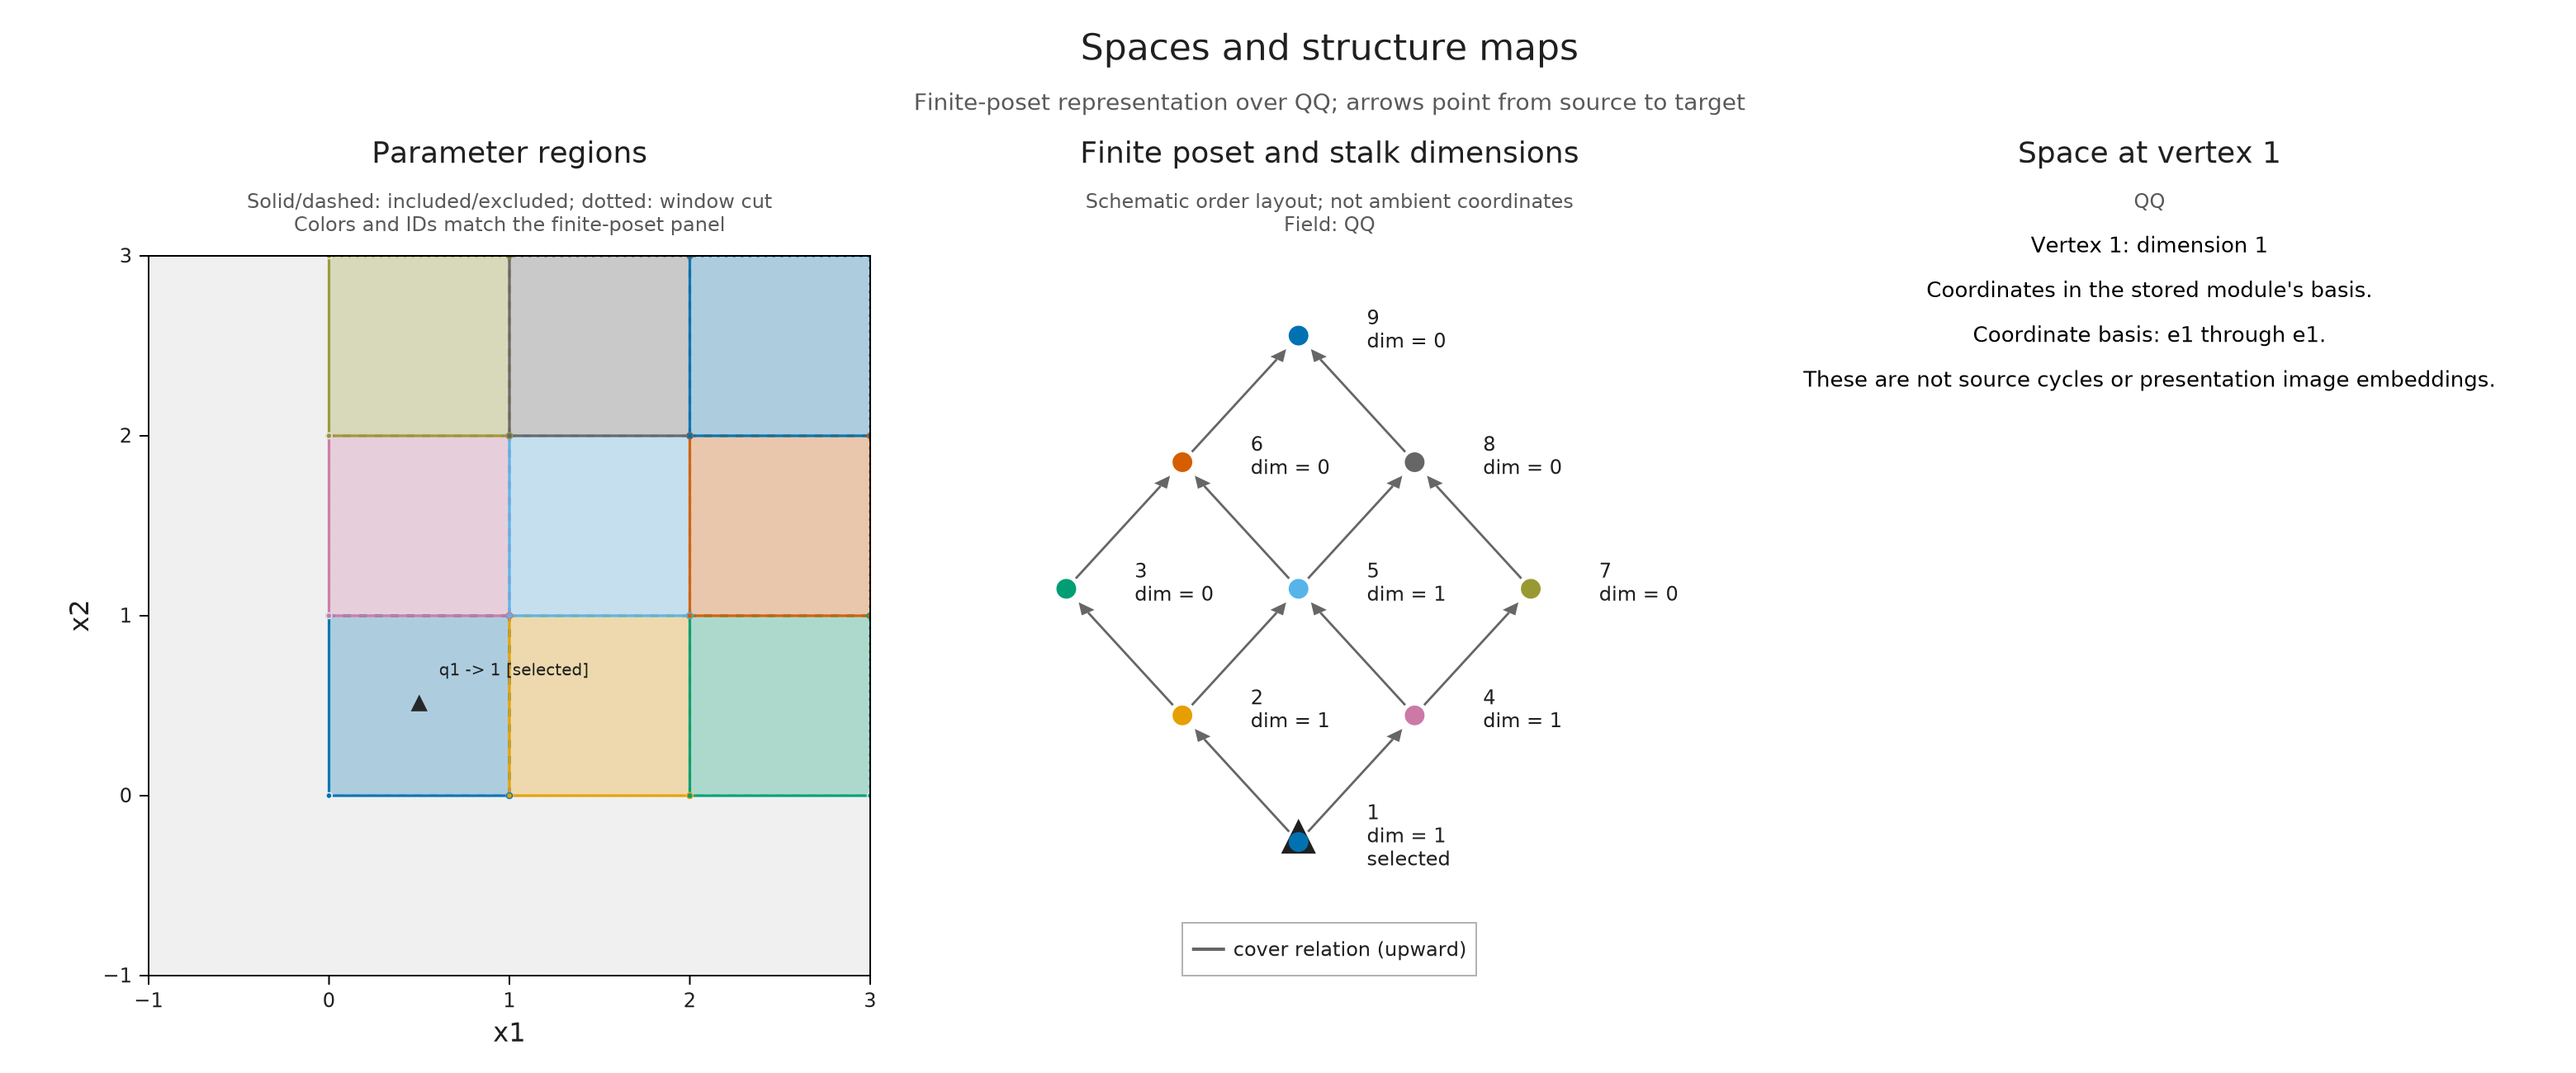

In [2]:
left_dims = [1, 1, 0, 1, 1, 0, 0, 0, 0]
right_dims = [1, 0, 0, 0]
M = OP.Advanced.PModule{OP.QQ}(P, left_dims,
    Dict((a,b) => ones(OP.QQ, left_dims[b], left_dims[a]) for (a,b) in OP.Advanced.cover_edges(P)); field)
N = OP.Advanced.PModule{OP.QQ}(R, right_dims,
    Dict((a,b) => ones(OP.QQ, right_dims[b], right_dims[a]) for (a,b) in OP.Advanced.cover_edges(R)); field)
left = OP.EncodingResult(P, M, OP.Advanced.GridEncodingMap(P, ([0,1,2], [0,1,2])))
right = OP.EncodingResult(R, N, OP.Advanced.GridEncodingMap(R, ([0,2], [0,2])))
OP.visualize(left; kind=:module_inspector, point=(1//2,1//2), box=((-1,-1),(3,3)))


The nine grid labels form a finite source for two classifiers. One is the identity; the other merges each pair of adjacent fine intervals. Their joint image contains nine label pairs, whereas the abstract Cartesian product contains 36. This finite witness alone certifies realization on those nine source labels. Here the displayed grid formulas additionally let us check the ambient fibers directly; a generic finite sample would not prove coverage of a continuous space.


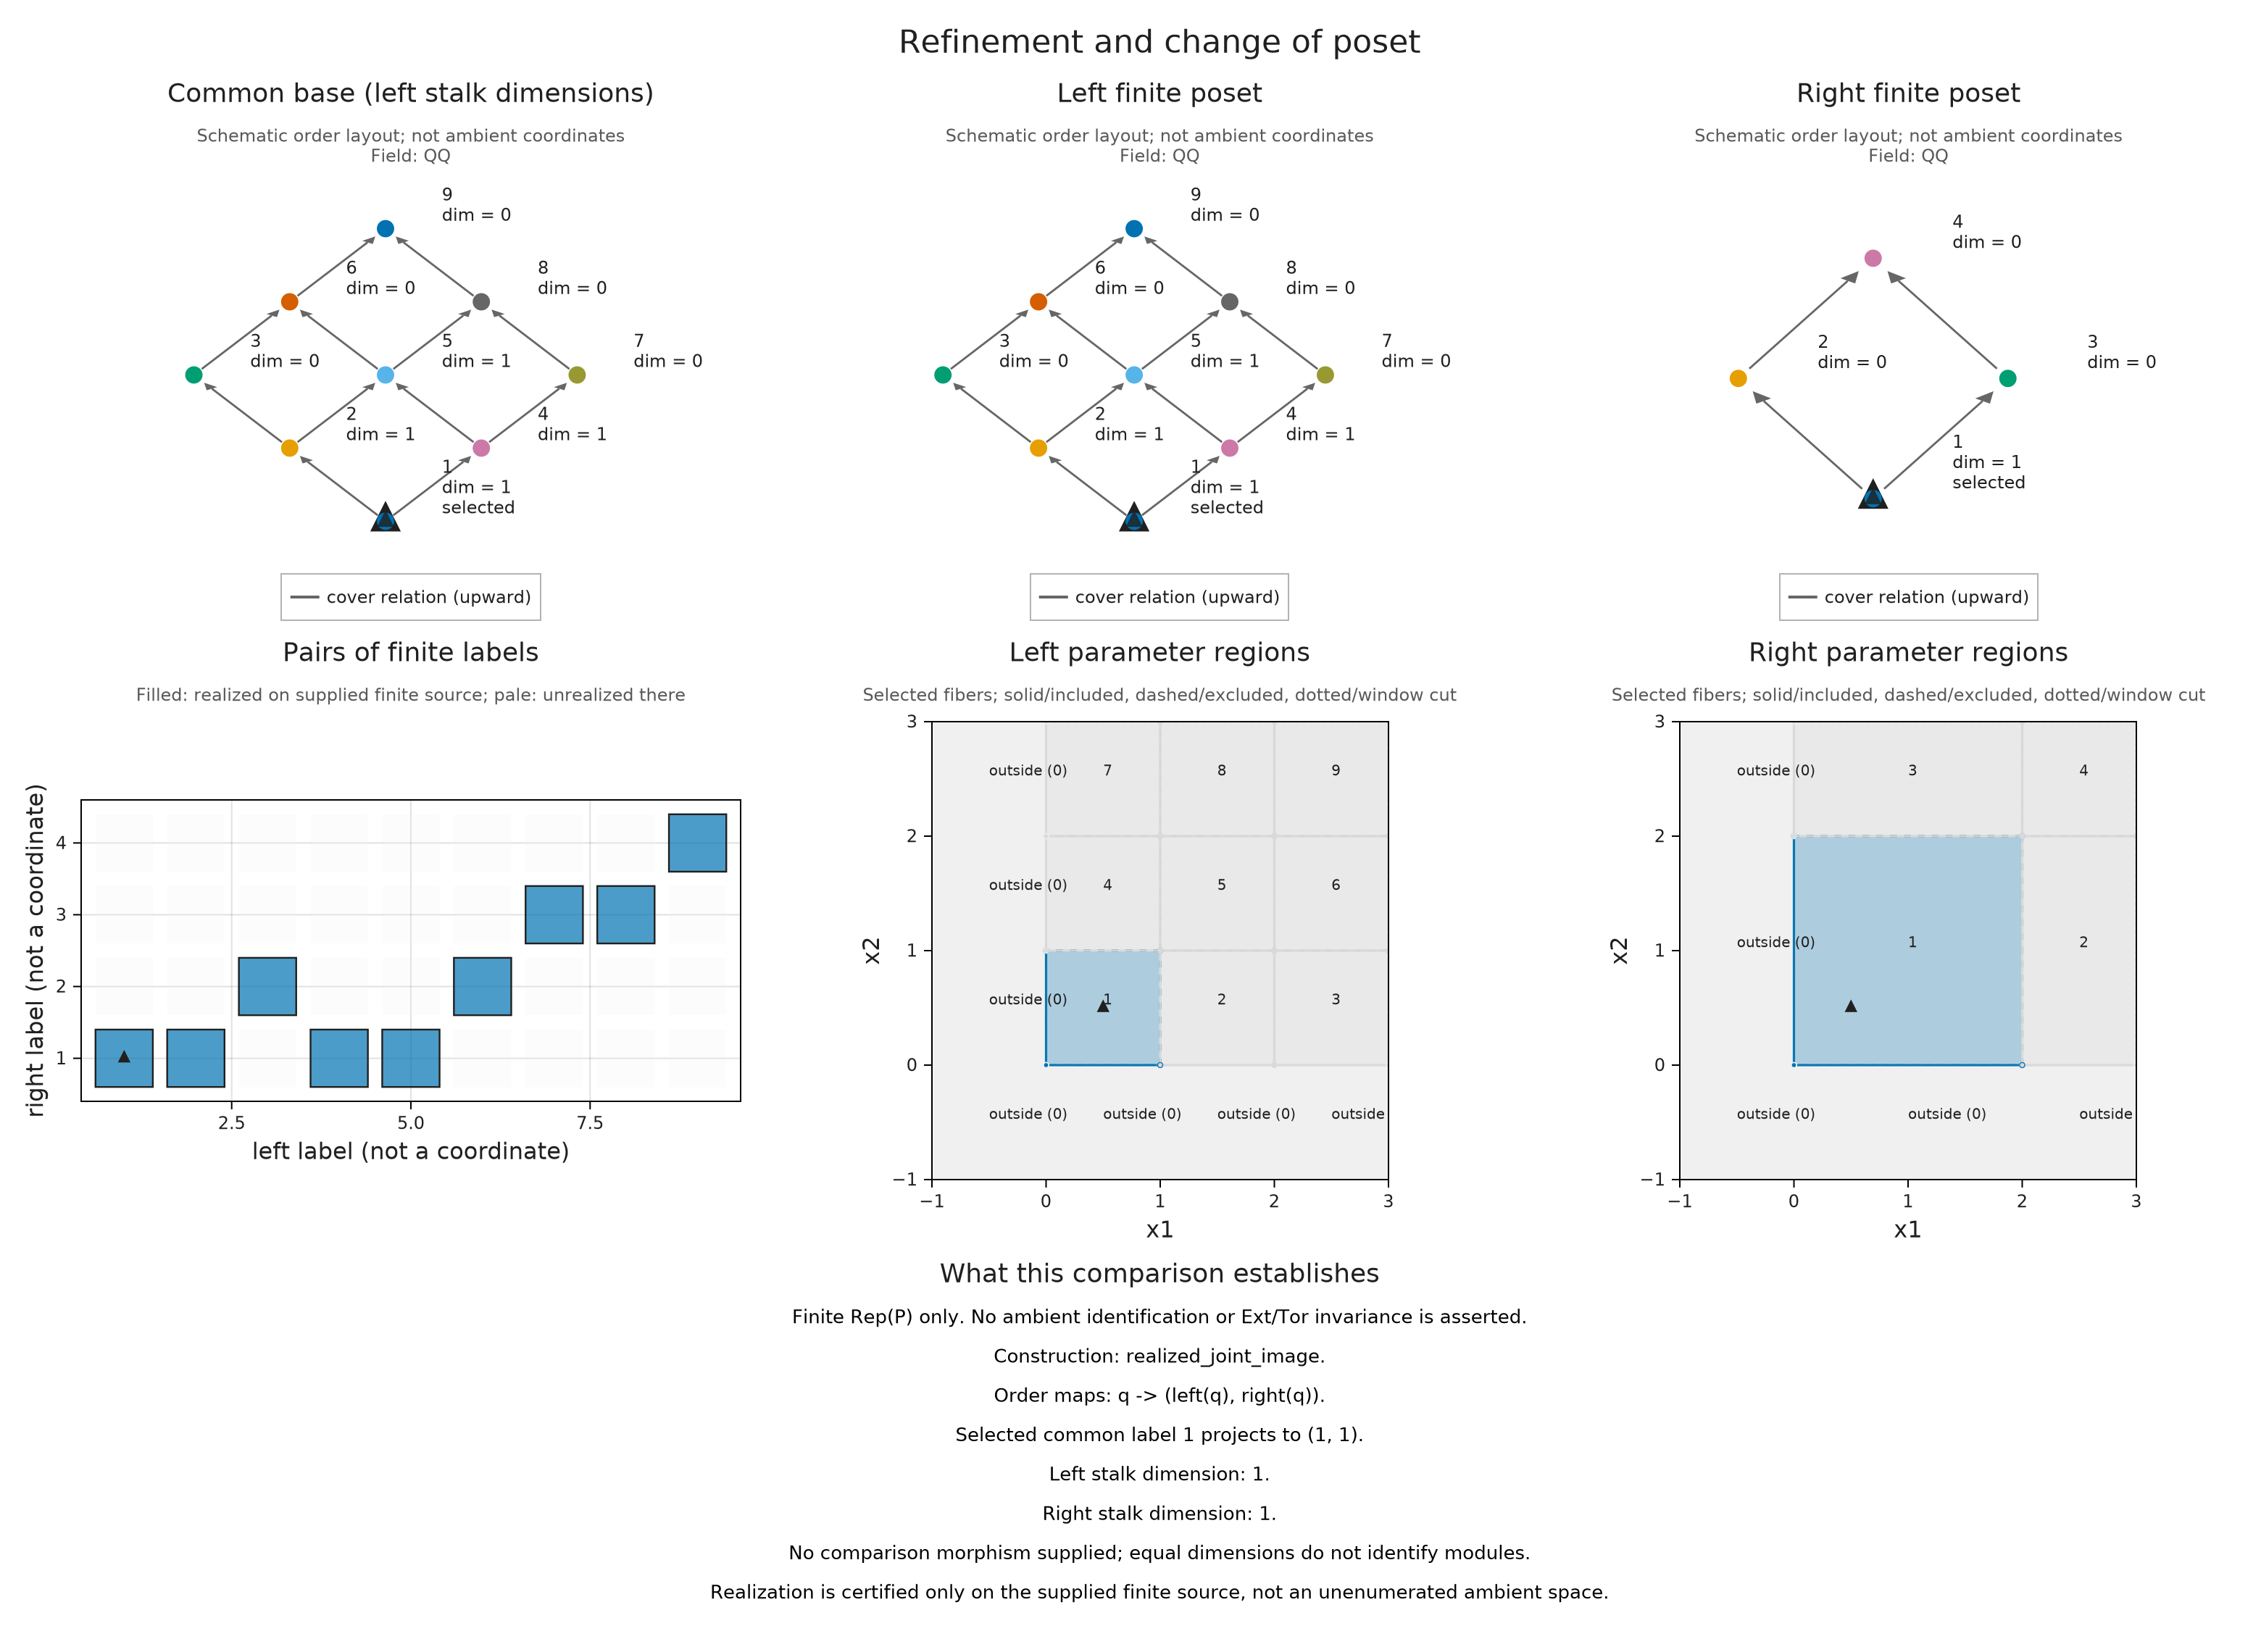

In [3]:
fine_classifier = OP.Advanced.EncodingMap(P, P, collect(1:9))
coarse_classifier = OP.Advanced.EncodingMap(P, R, [1,1,2,1,1,2,3,3,4])
joint = OP.Advanced.joint_encoding(fine_classifier, coarse_classifier)
refined = OP.common_refinement(left, right, joint)
OP.visualize(refined; sources=(left,right), joint, point=(1//2,1//2), box=((-1,-1),(3,3)))


Selecting a coarse label can have several fine preimages. All candidates remain visible. The viewer does not choose a preferred representative for you.


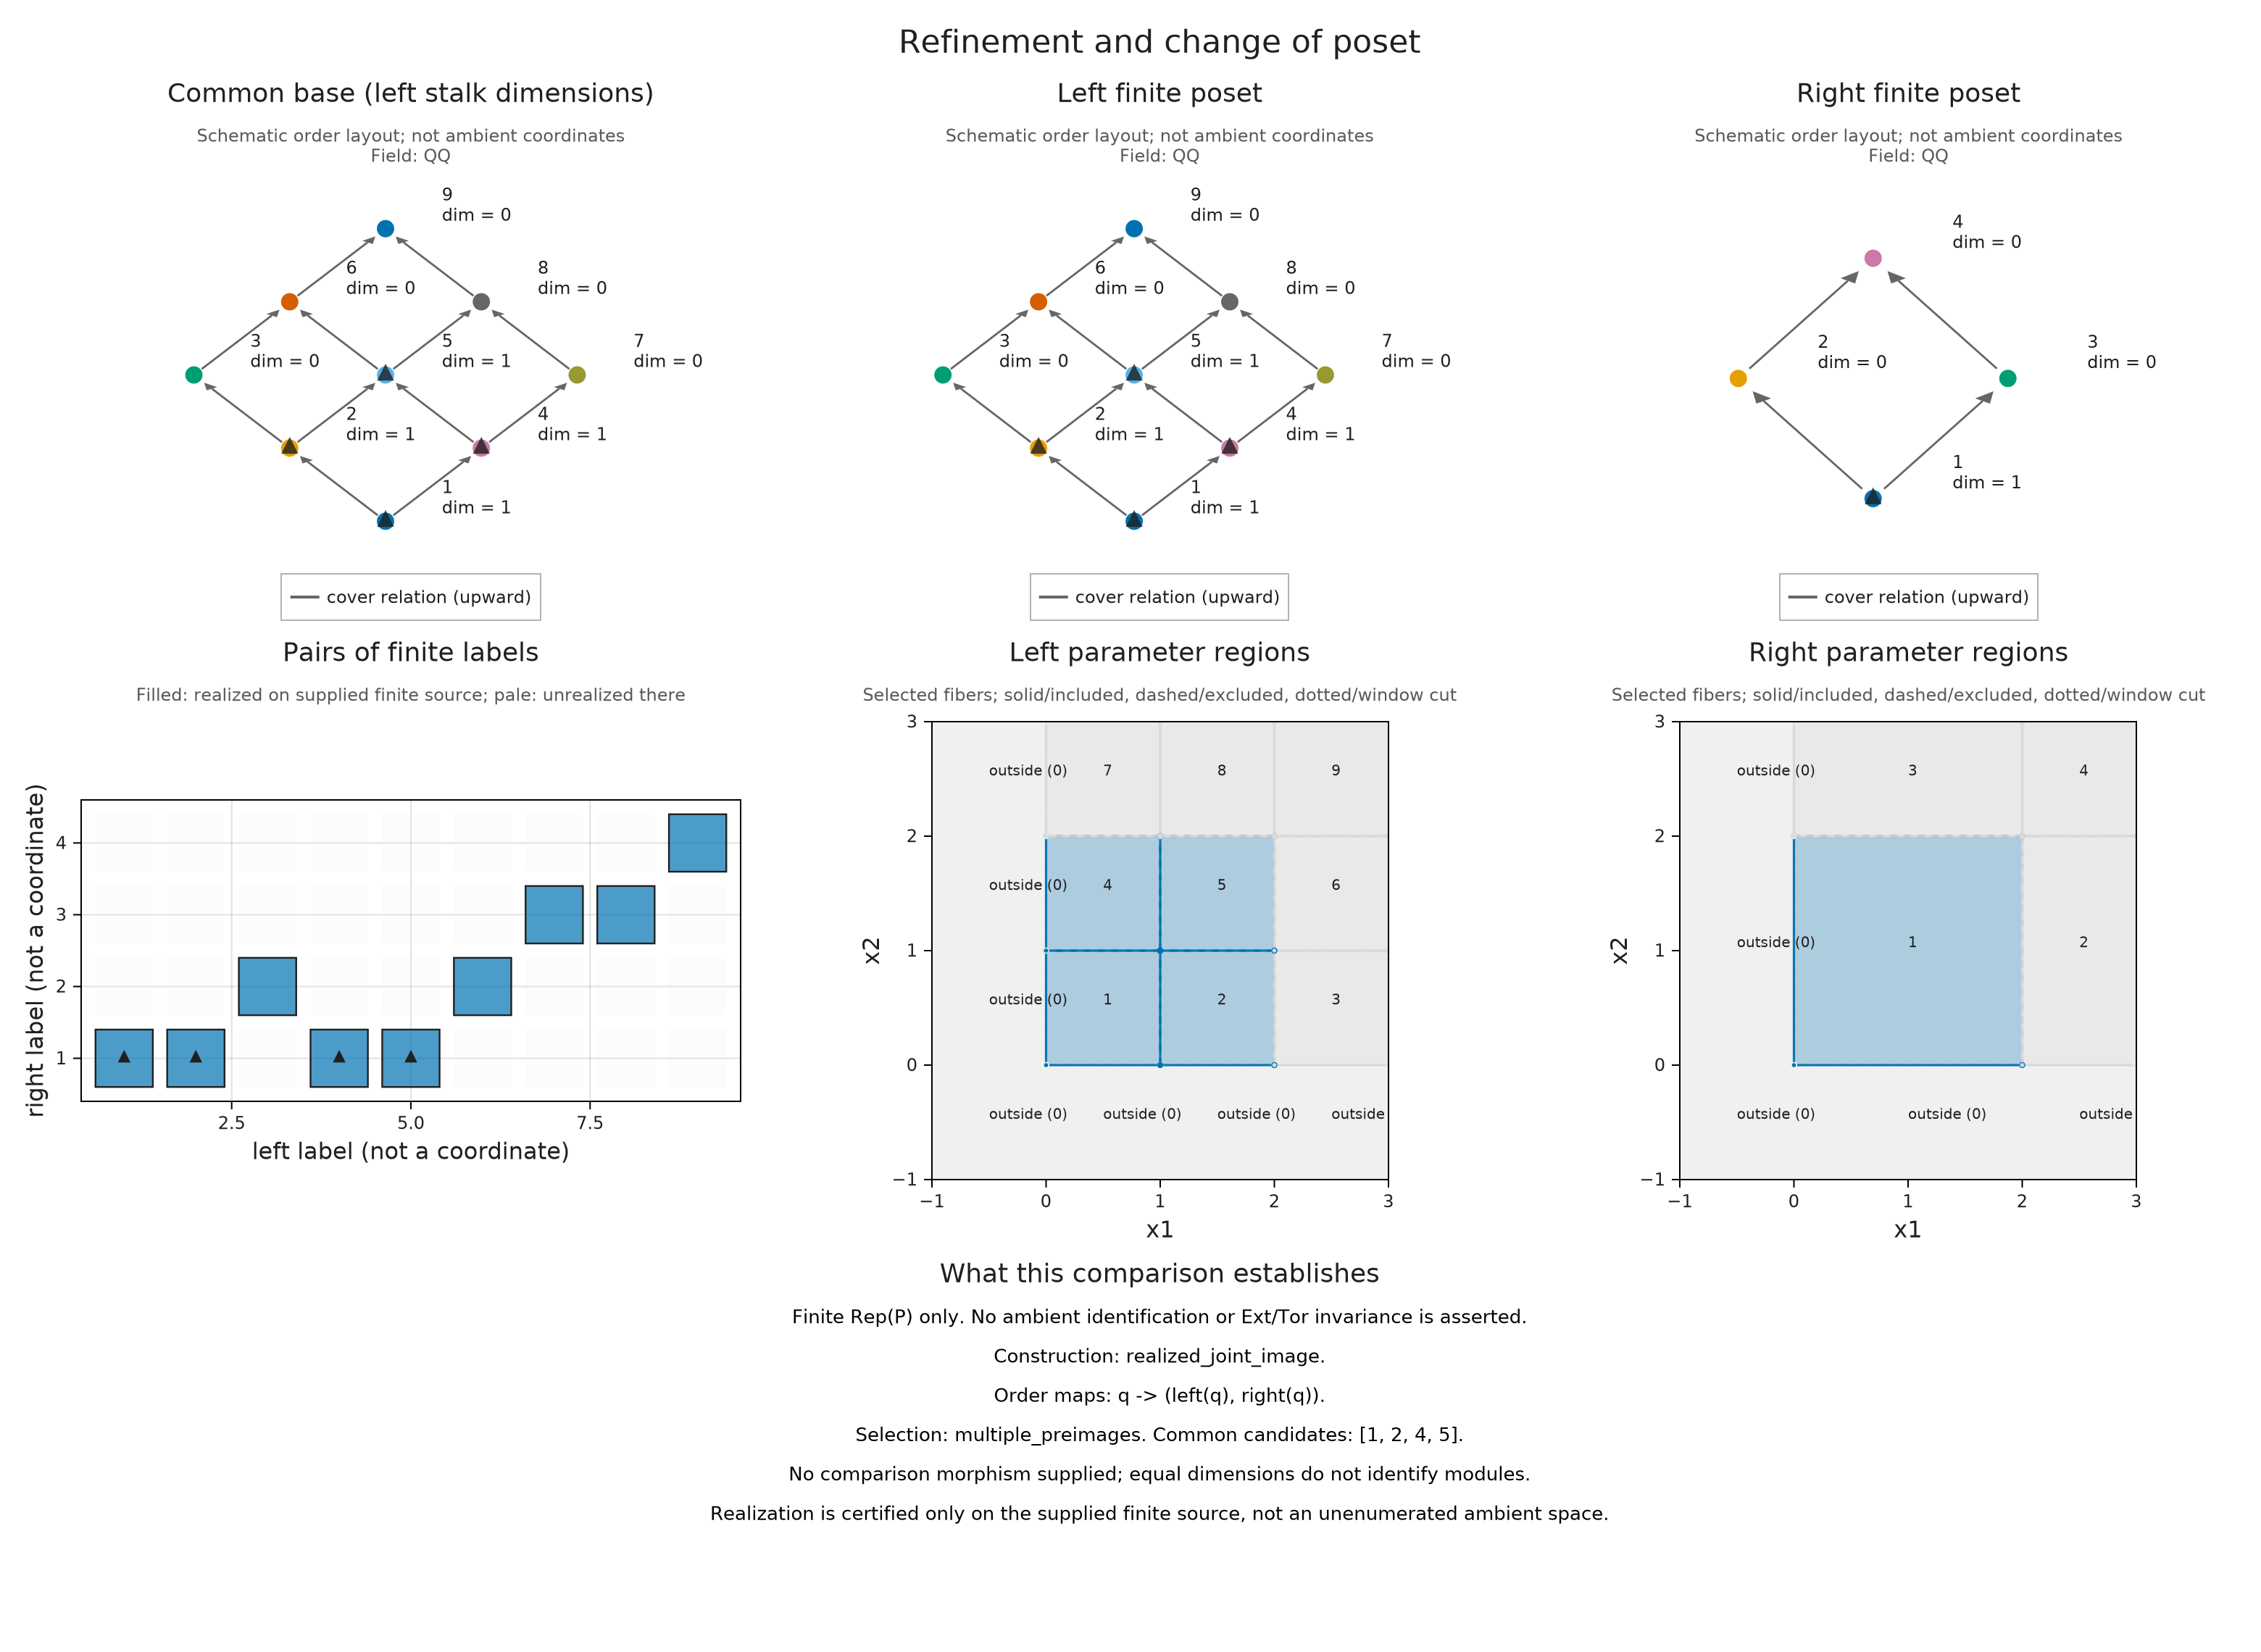

In [4]:
OP.visualize(refined; sources=(left,right), joint, side=:right, label=1, box=((-1,-1),(3,3)))


## Supply the identification, then check its squares

Both restrictions now live on the common poset. We supply identity matrices in their stored stalk coordinates. The inspector checks every cover square and whether every component is invertible. For the selected pair it displays both composite matrices, so the equality is inspectable rather than inferred from dimensions.


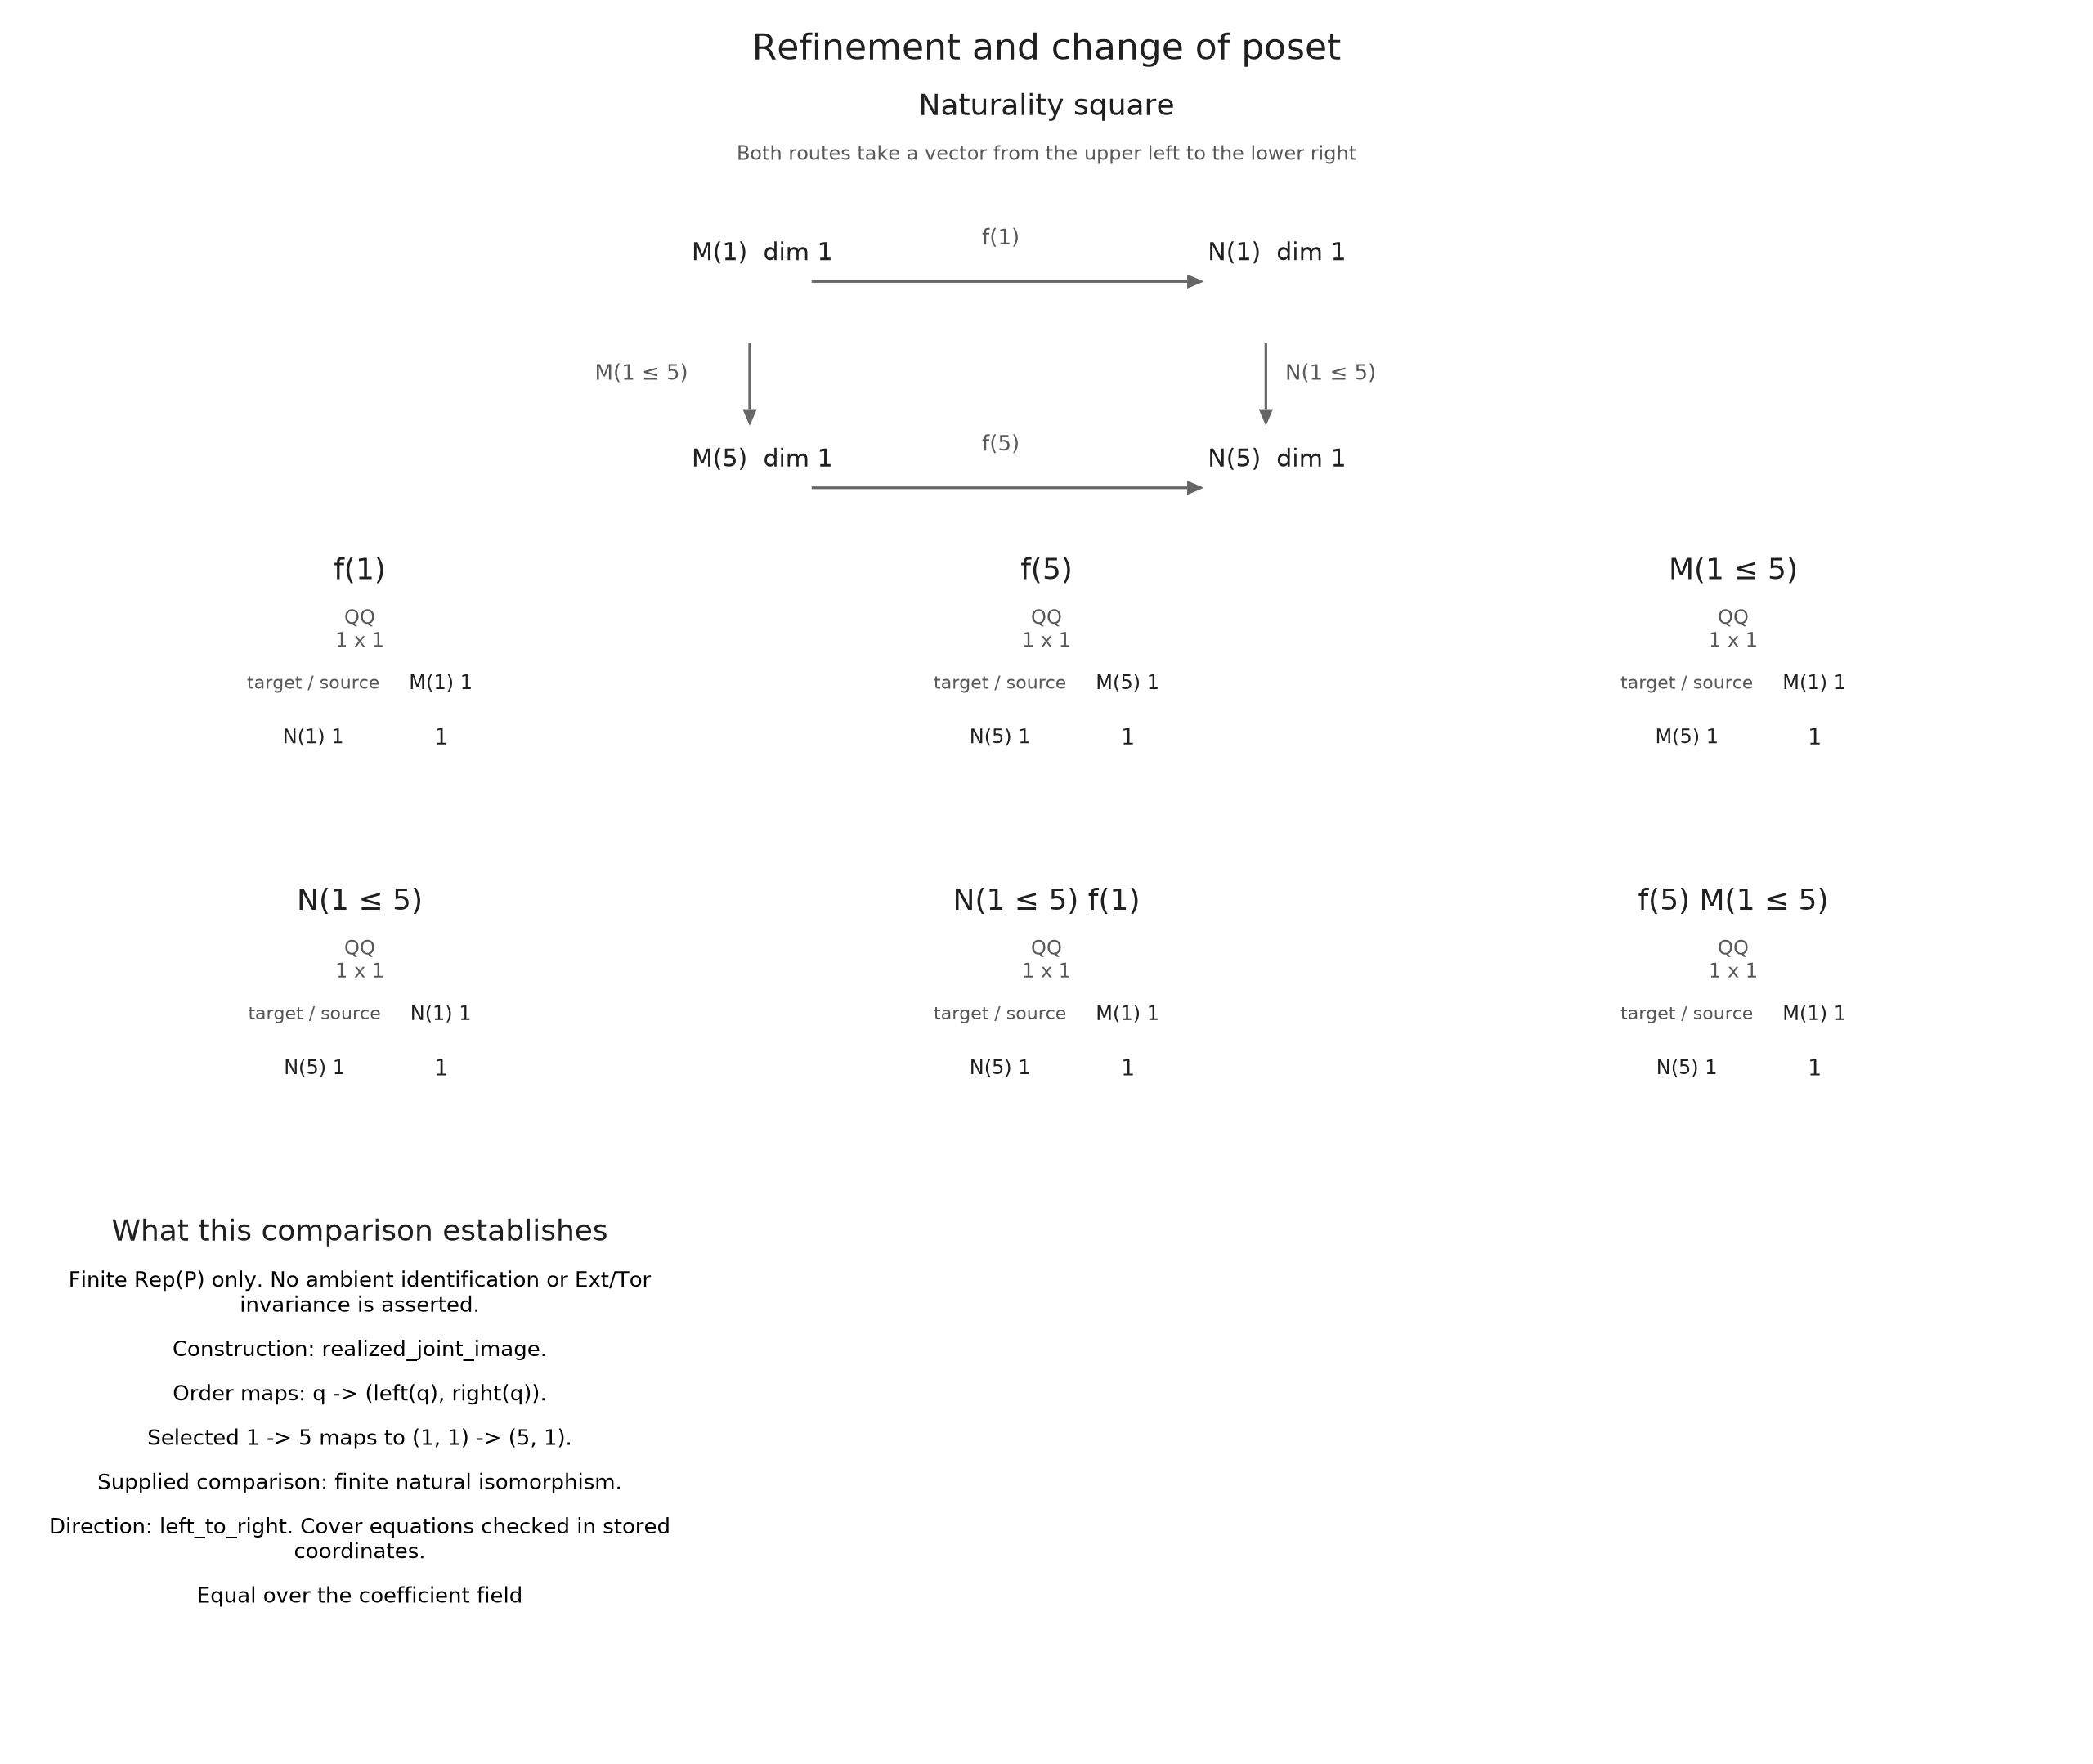

In [5]:
modules = OP.Advanced.translated_modules(refined)
comparison = OP.Advanced.PMorphism(modules.left, modules.right,
    [Matrix{OP.QQ}(I,d,d) for d in OP.dimensions(modules.left).stalks])
OP.visualize(refined; comparison, pair=(1,5), view=:square)


A zero target is still a defined map. Selecting label 9 keeps the empty rows in the matrix data. Selecting two incomparable labels, by contrast, produces no forward square.


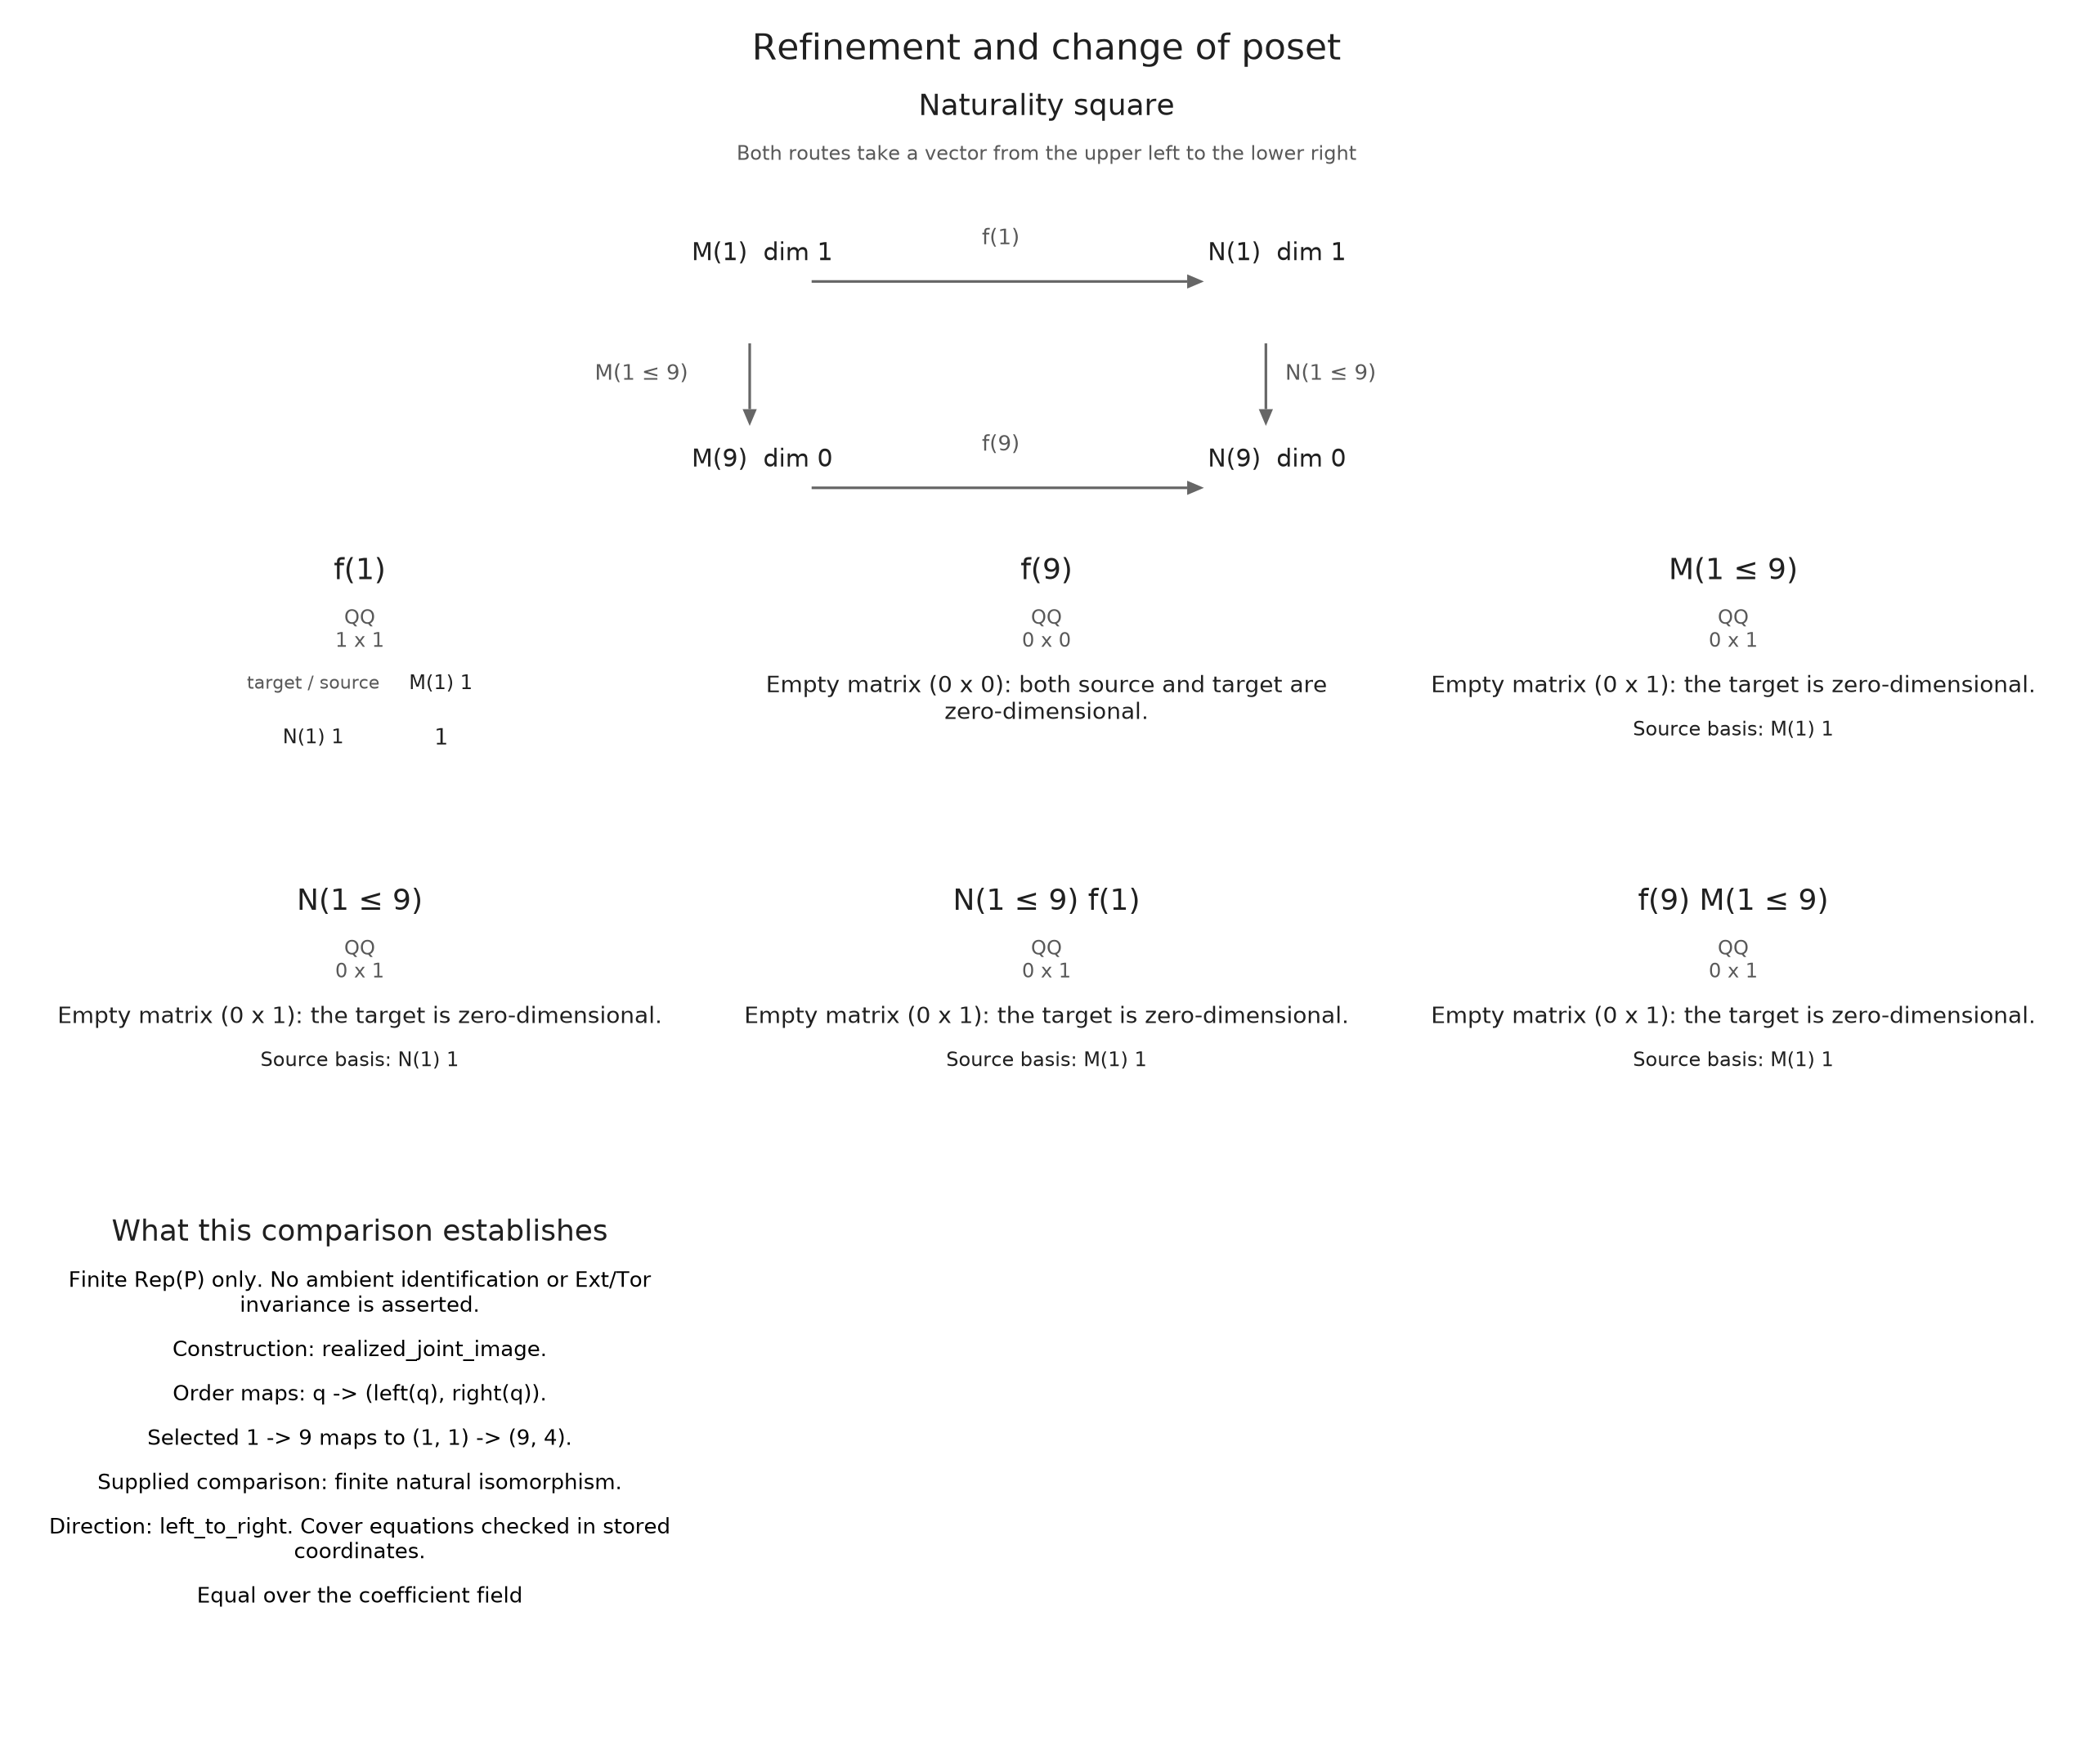

In [6]:
OP.visualize(refined; comparison, pair=(1,9), view=:square)


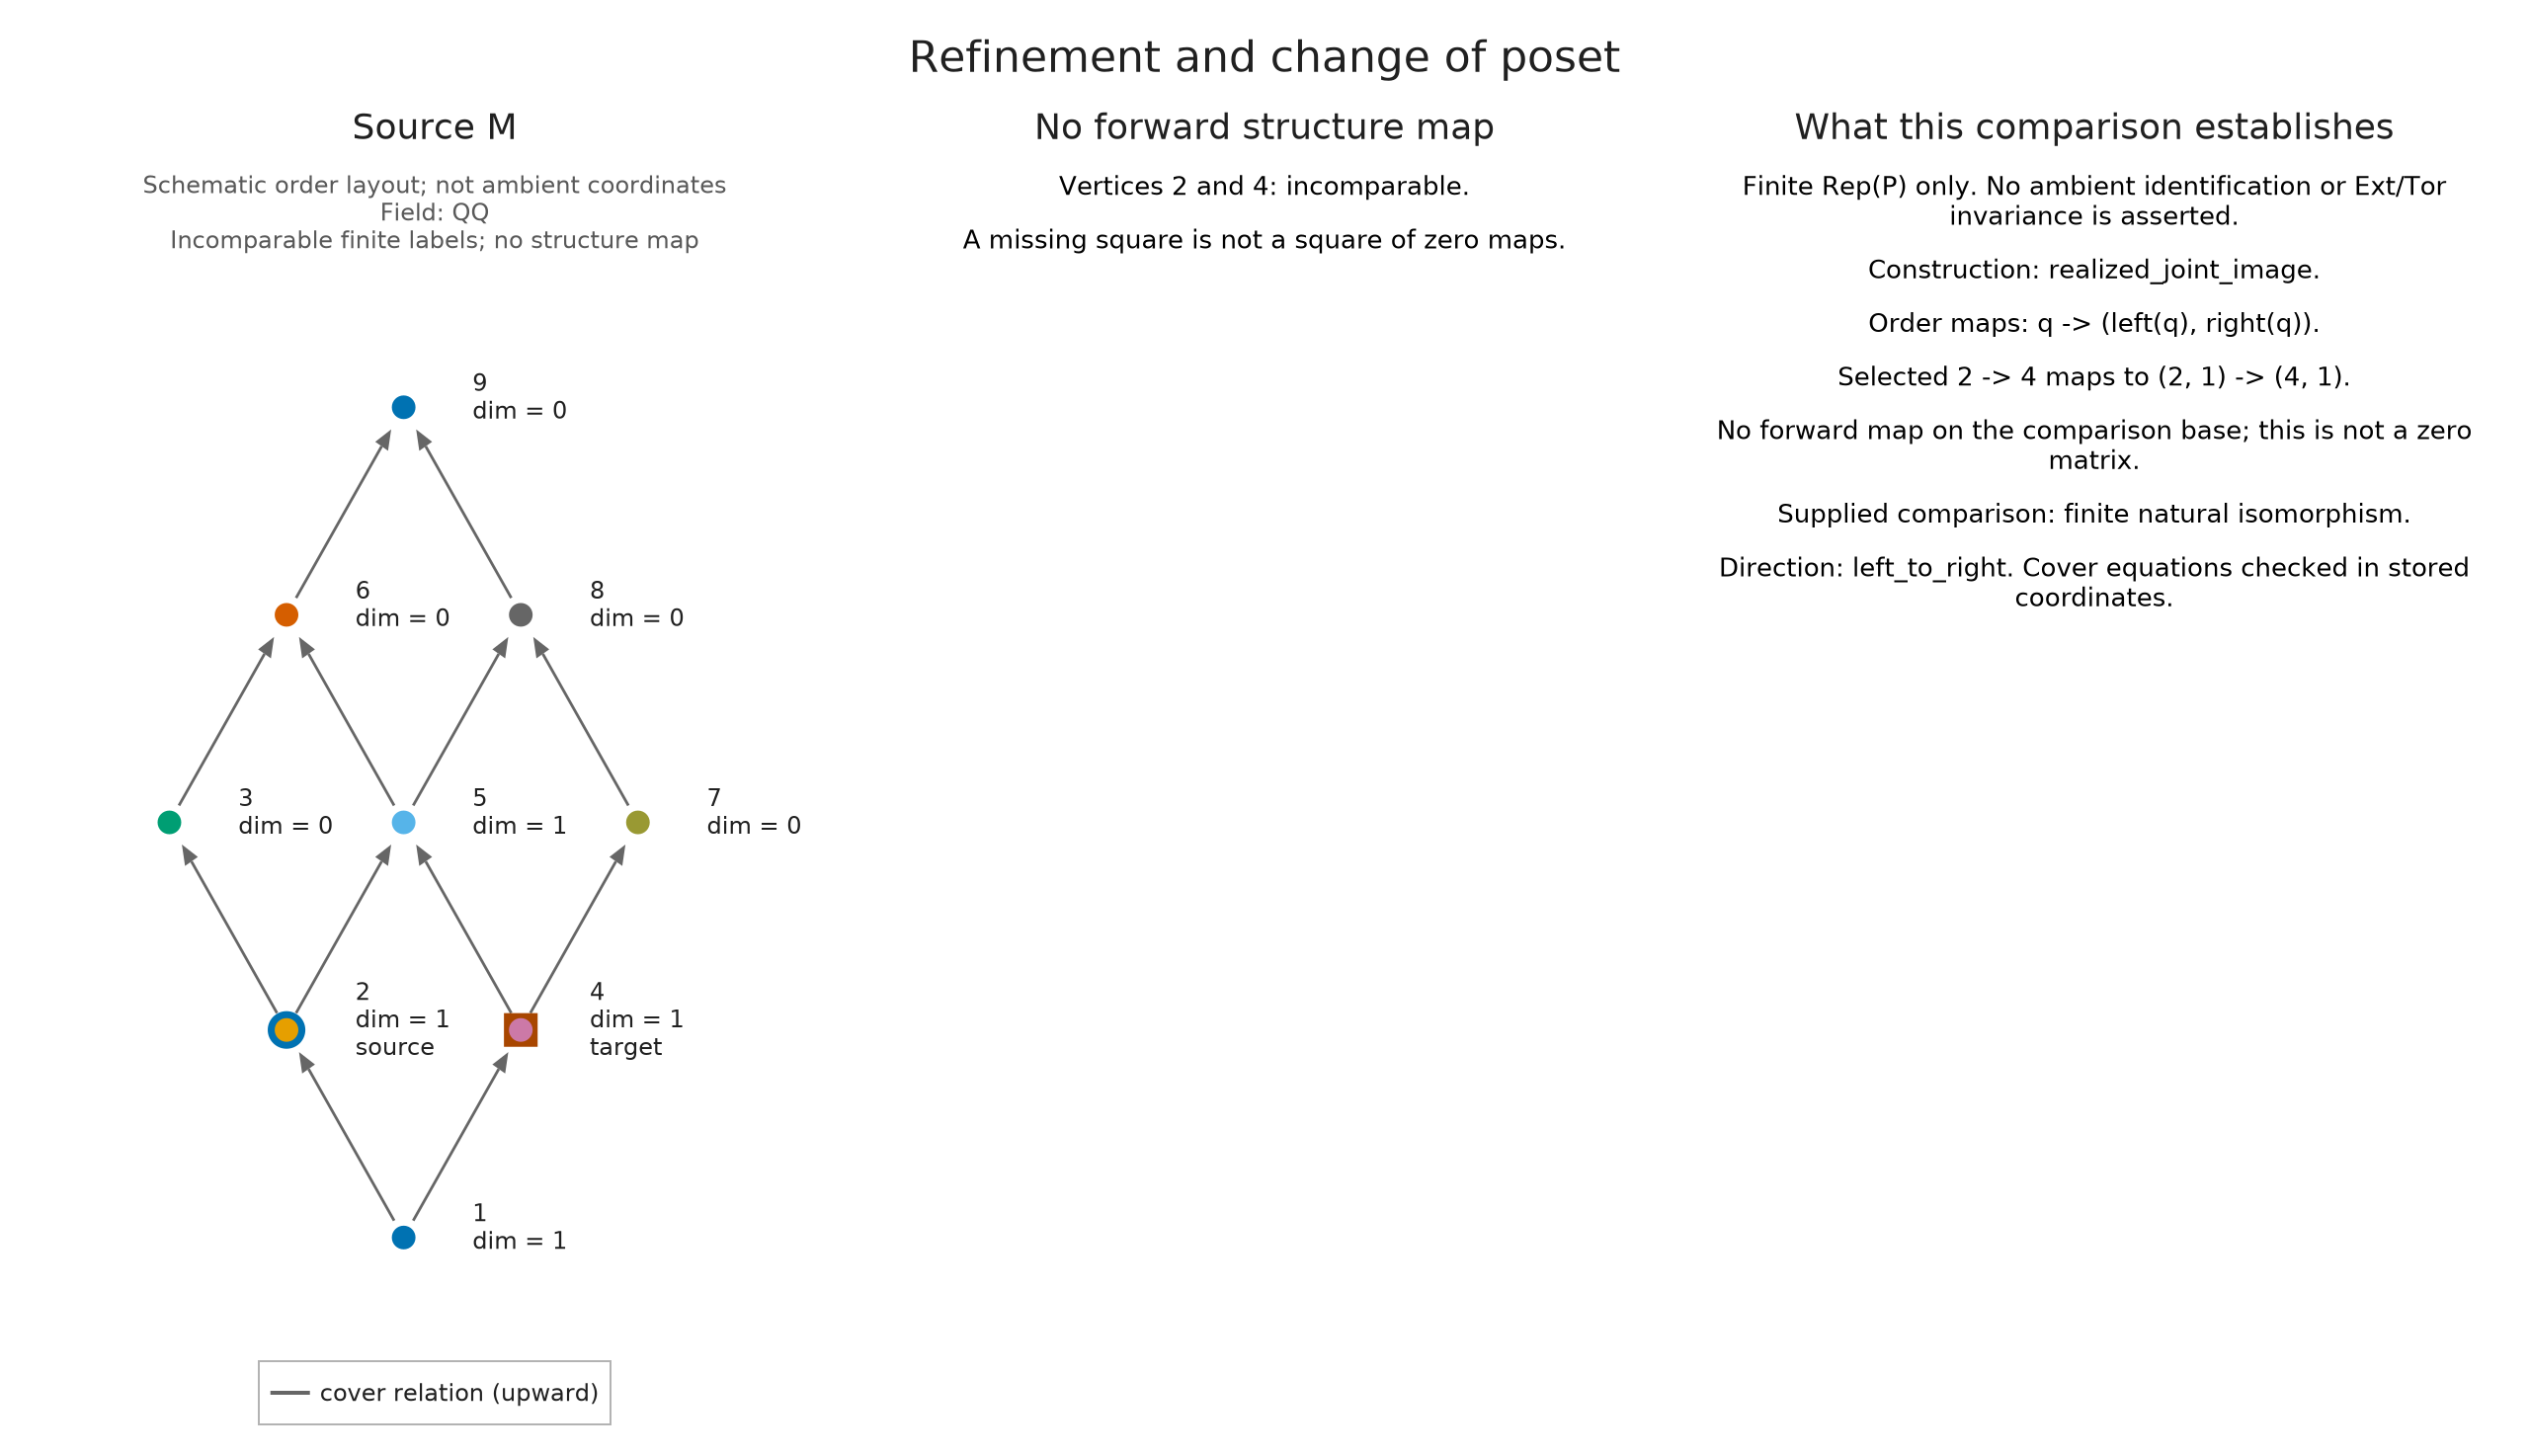

In [7]:
OP.visualize(refined; comparison, pair=(2,4), view=:square)


Restriction can also be inspected on its own. Its order map runs from the new base to the old base. Both displayed maps below are computed from the actual modules.


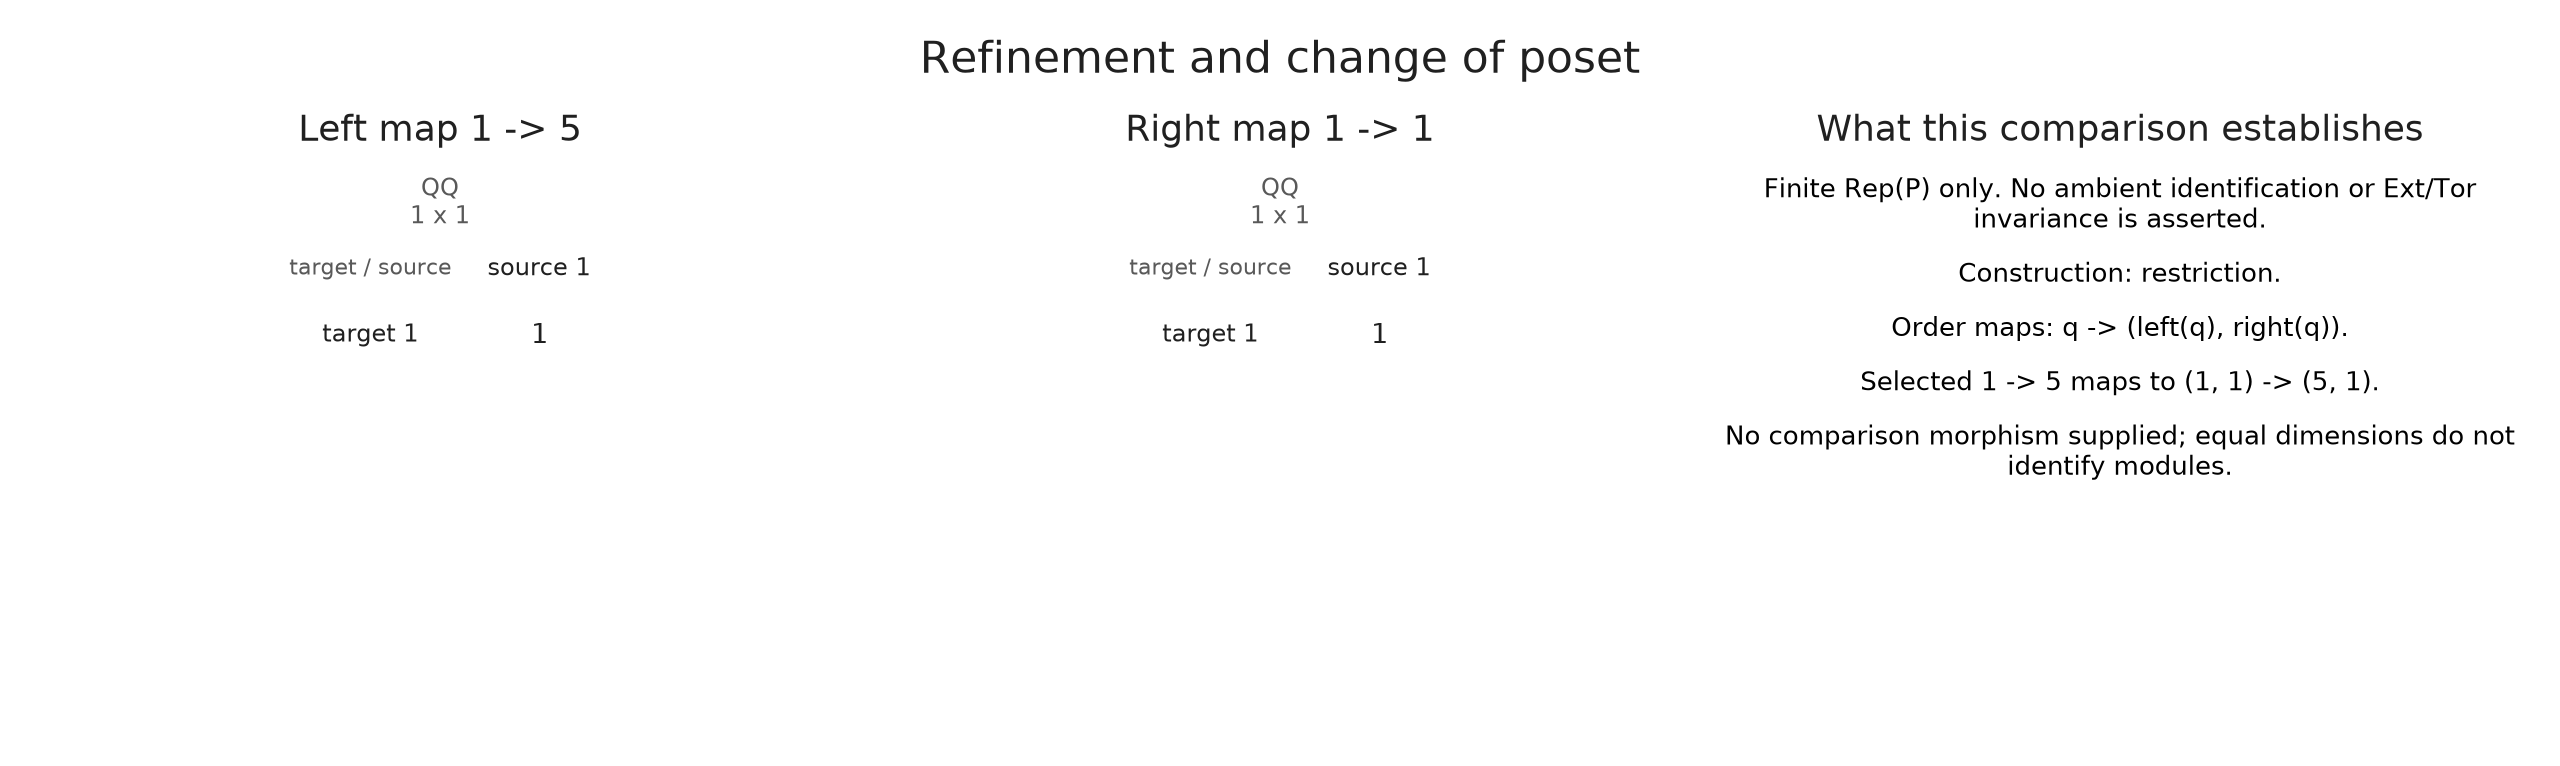

In [8]:
restricted = OP.restriction(coarse_classifier, right)
OP.visualize(restricted; pair=(1,5), view=:square)


Without a joint witness, the ordinary common-refinement constructor uses an abstract product when its bases differ. Passing the finite witness to the viewer marks which product pairs occur on that source; it does not change the product module or erase its other labels.


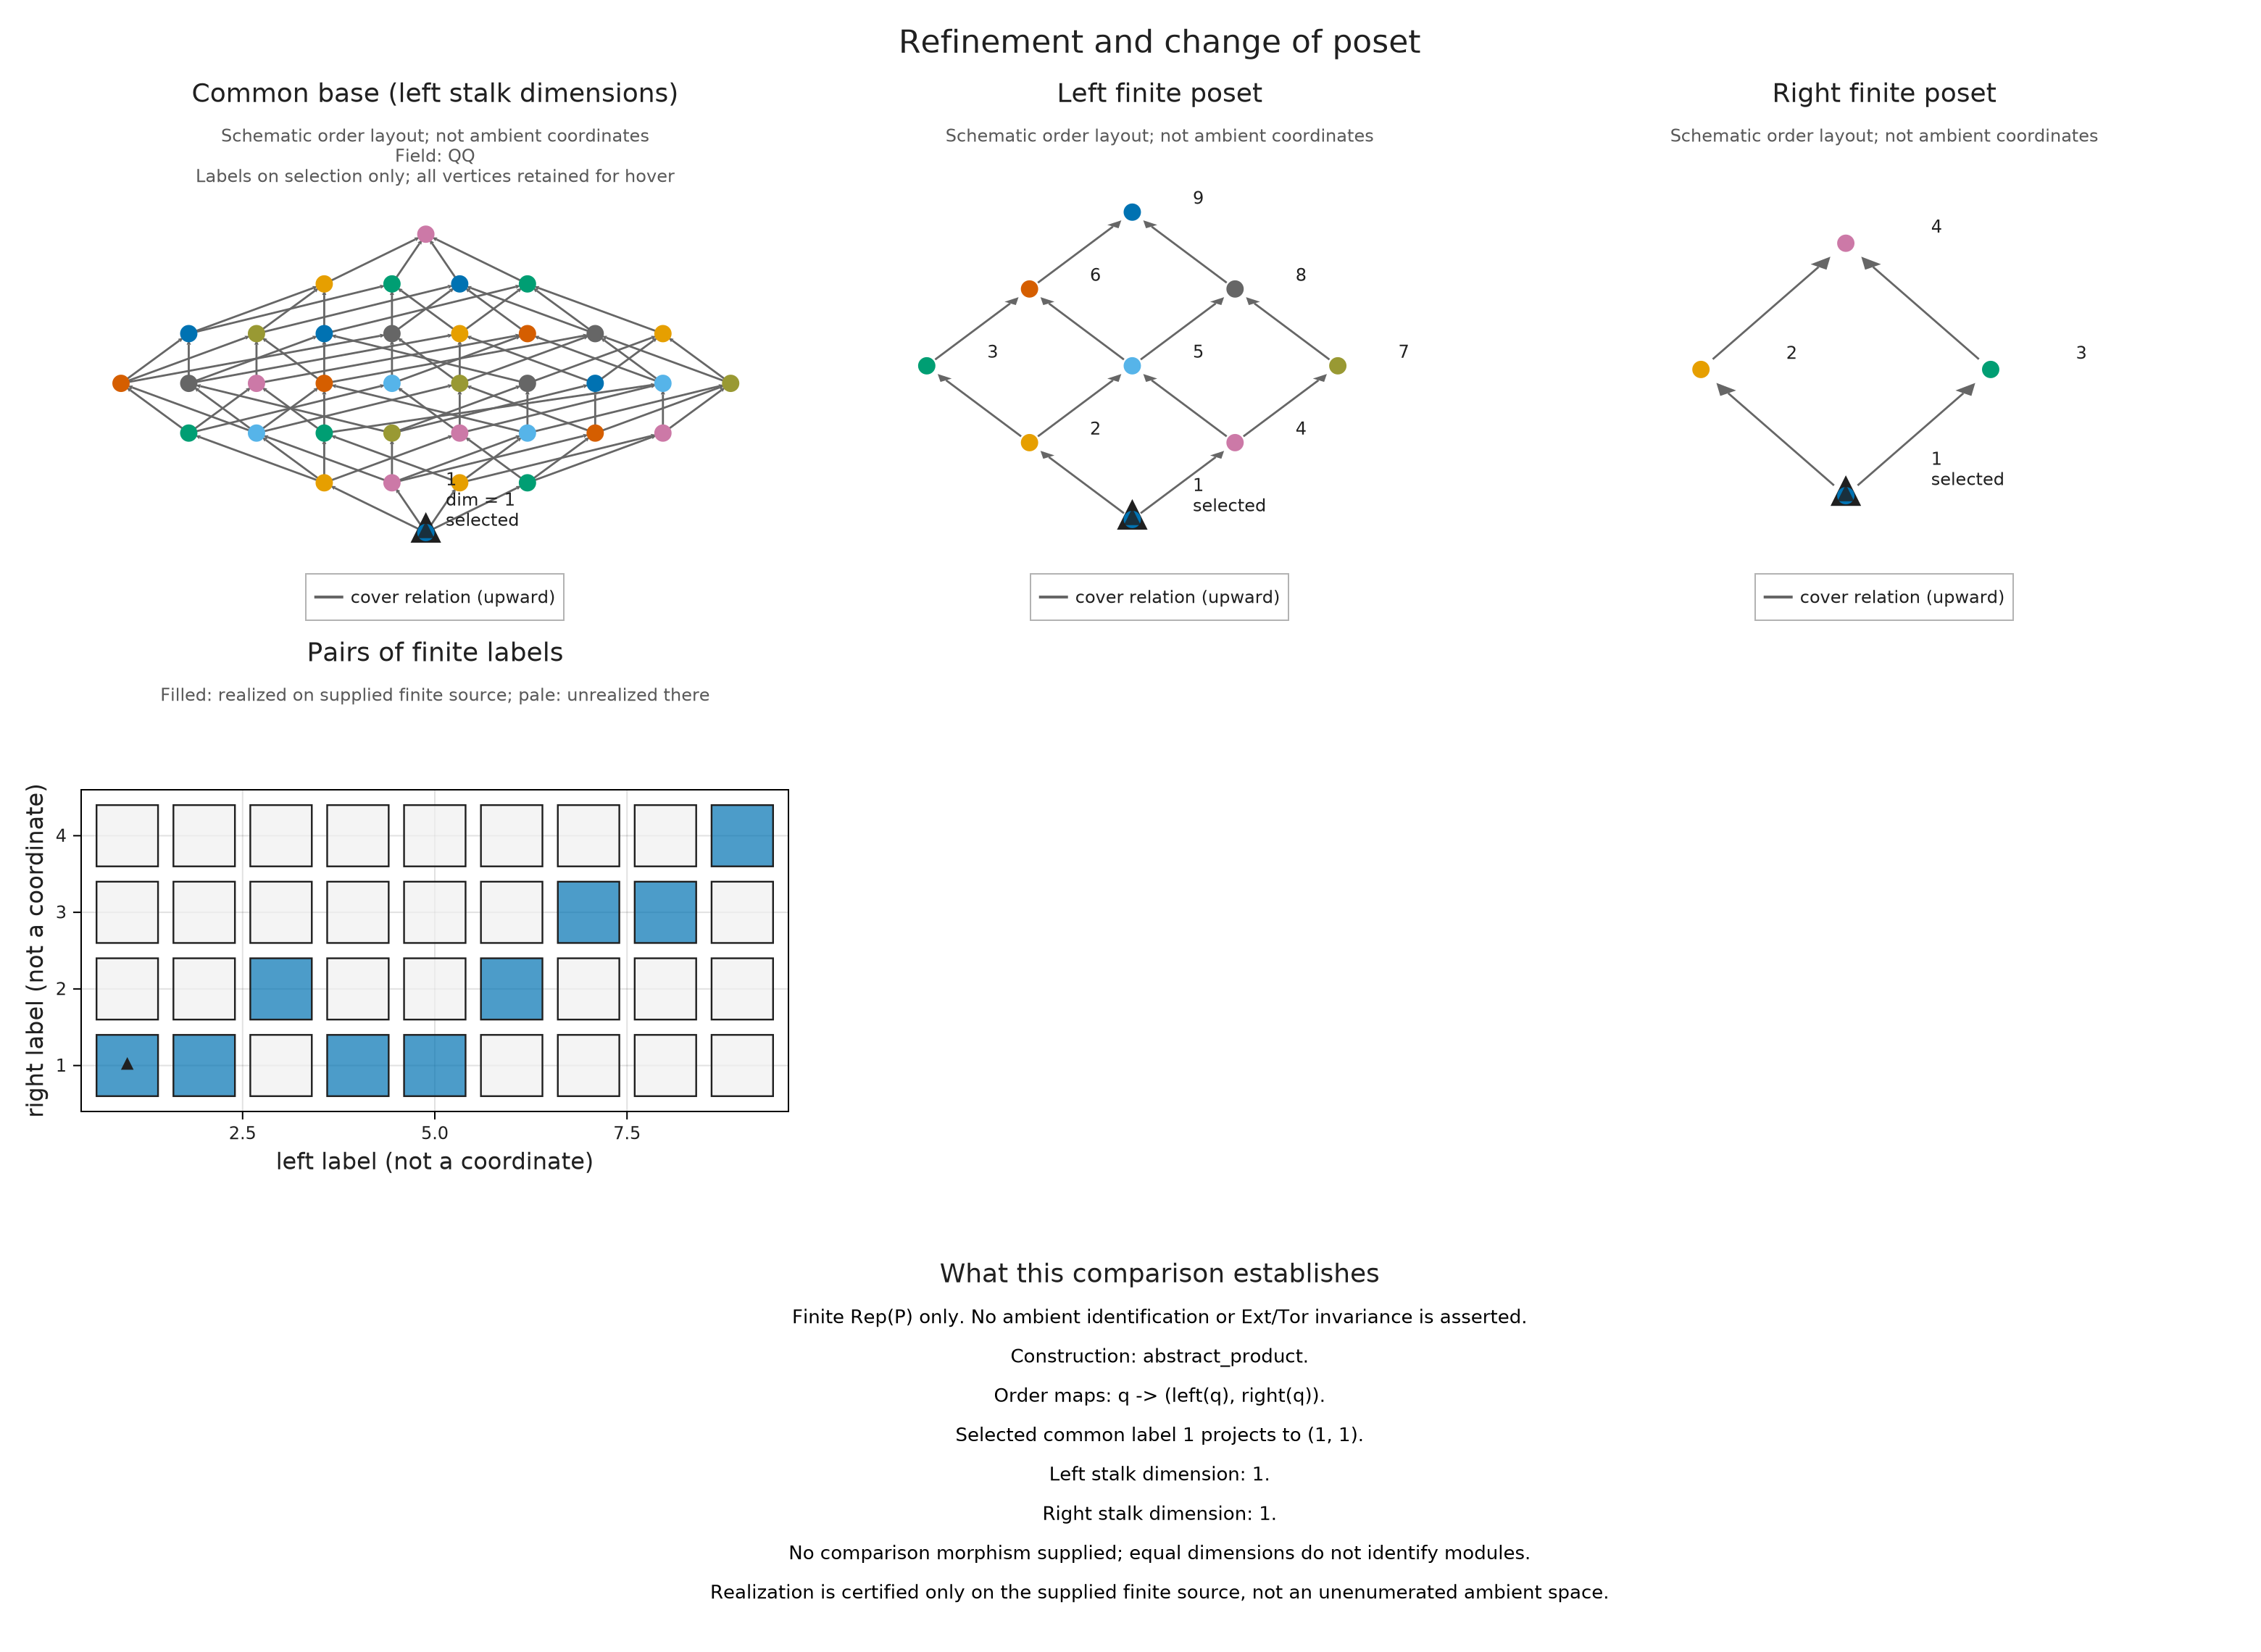

In [9]:
product = OP.common_refinement(left, right)
OP.visualize(product; joint, vertex=1)


## A Kan comparison does not identify finite derived categories

Let $Q$ have two minimal and two maximal elements, each minimum below each maximum. Its order complex is a four-edge cycle. Collapse $Q$ to one point and take the constant one-dimensional module. The left Kan unit happens to be an isomorphism on this module. Nevertheless, its degree-one self-Ext has dimension one in $\mathrm{Rep}(Q)$ and zero in the category of vector spaces at one point.

The finite base is part of a derived computation. The [category lesson](../math_categories.md) explains this distinction.


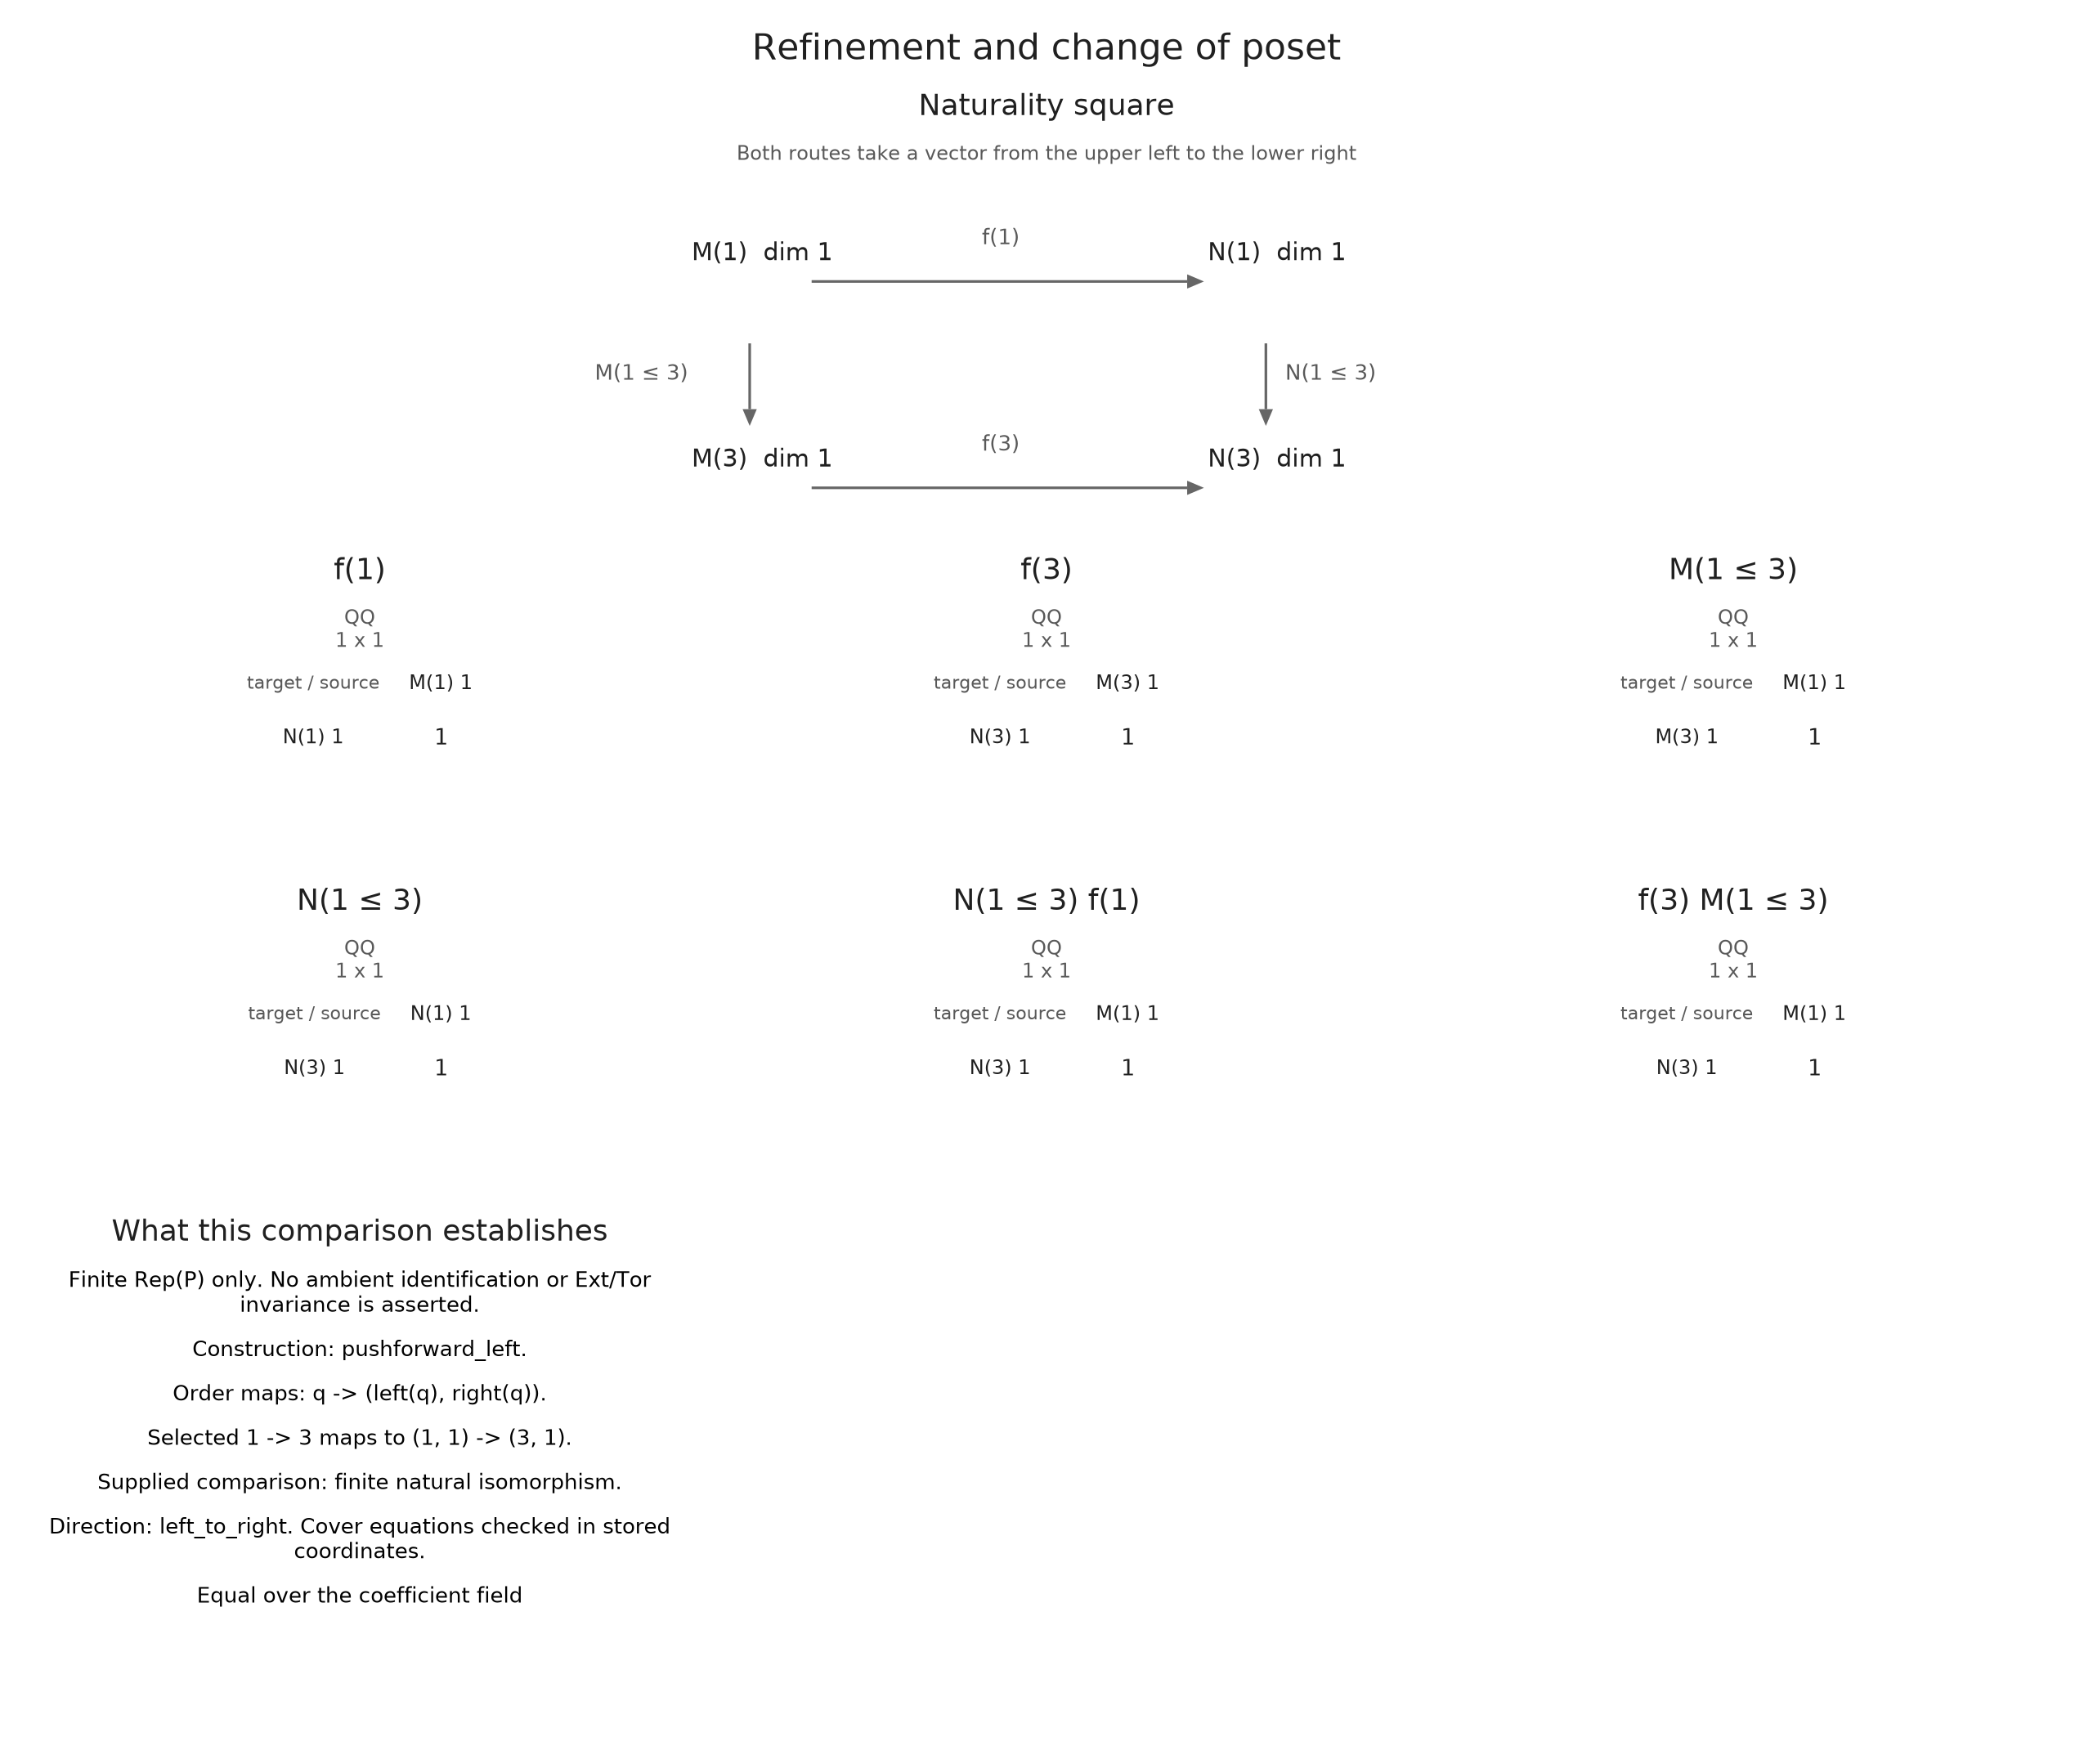

In [10]:
Q = OP.Advanced.FinitePoset(Bool[1 0 1 1; 0 1 1 1; 0 0 1 0; 0 0 0 1])
point_poset = OP.Advanced.FinitePoset(trues(1,1))
C = OP.Advanced.PModule{OP.QQ}(Q, ones(Int,4),
    Dict(edge => ones(OP.QQ,1,1) for edge in OP.Advanced.cover_edges(Q)); field)
collapse = OP.Advanced.EncodingMap(Q, point_poset, ones(Int,4))
encoded_C = OP.EncodingResult(Q,C,nothing)
transported = OP.pushforward_left(collapse, encoded_C)
unit = OP.Advanced.kan_unit(collapse,C)
OP.visualize(transported; comparison=unit, pair=(1,3), view=:square)


In [11]:
options = OP.Advanced.DerivedFunctorOptions(maxdeg=1, model=:projective)
V = OP.translated_module(transported)
self_ext_Q = OP.Advanced.Ext(C,C,options)
self_ext_point = OP.Advanced.Ext(V,V,options)
@assert OP.Advanced.dim(self_ext_Q,1) == 1
@assert OP.Advanced.dim(self_ext_point,1) == 0
(ext1_on_Q=OP.Advanced.dim(self_ext_Q,1), ext1_on_point=OP.Advanced.dim(self_ext_point,1))


(ext1_on_Q = 1, ext1_on_point = 0)

The right Kan counit reverses the comparison direction on the source base. Compute it explicitly and declare that direction to the viewer. Drawing a transport result never computes a missing Kan extension, unit or counit.


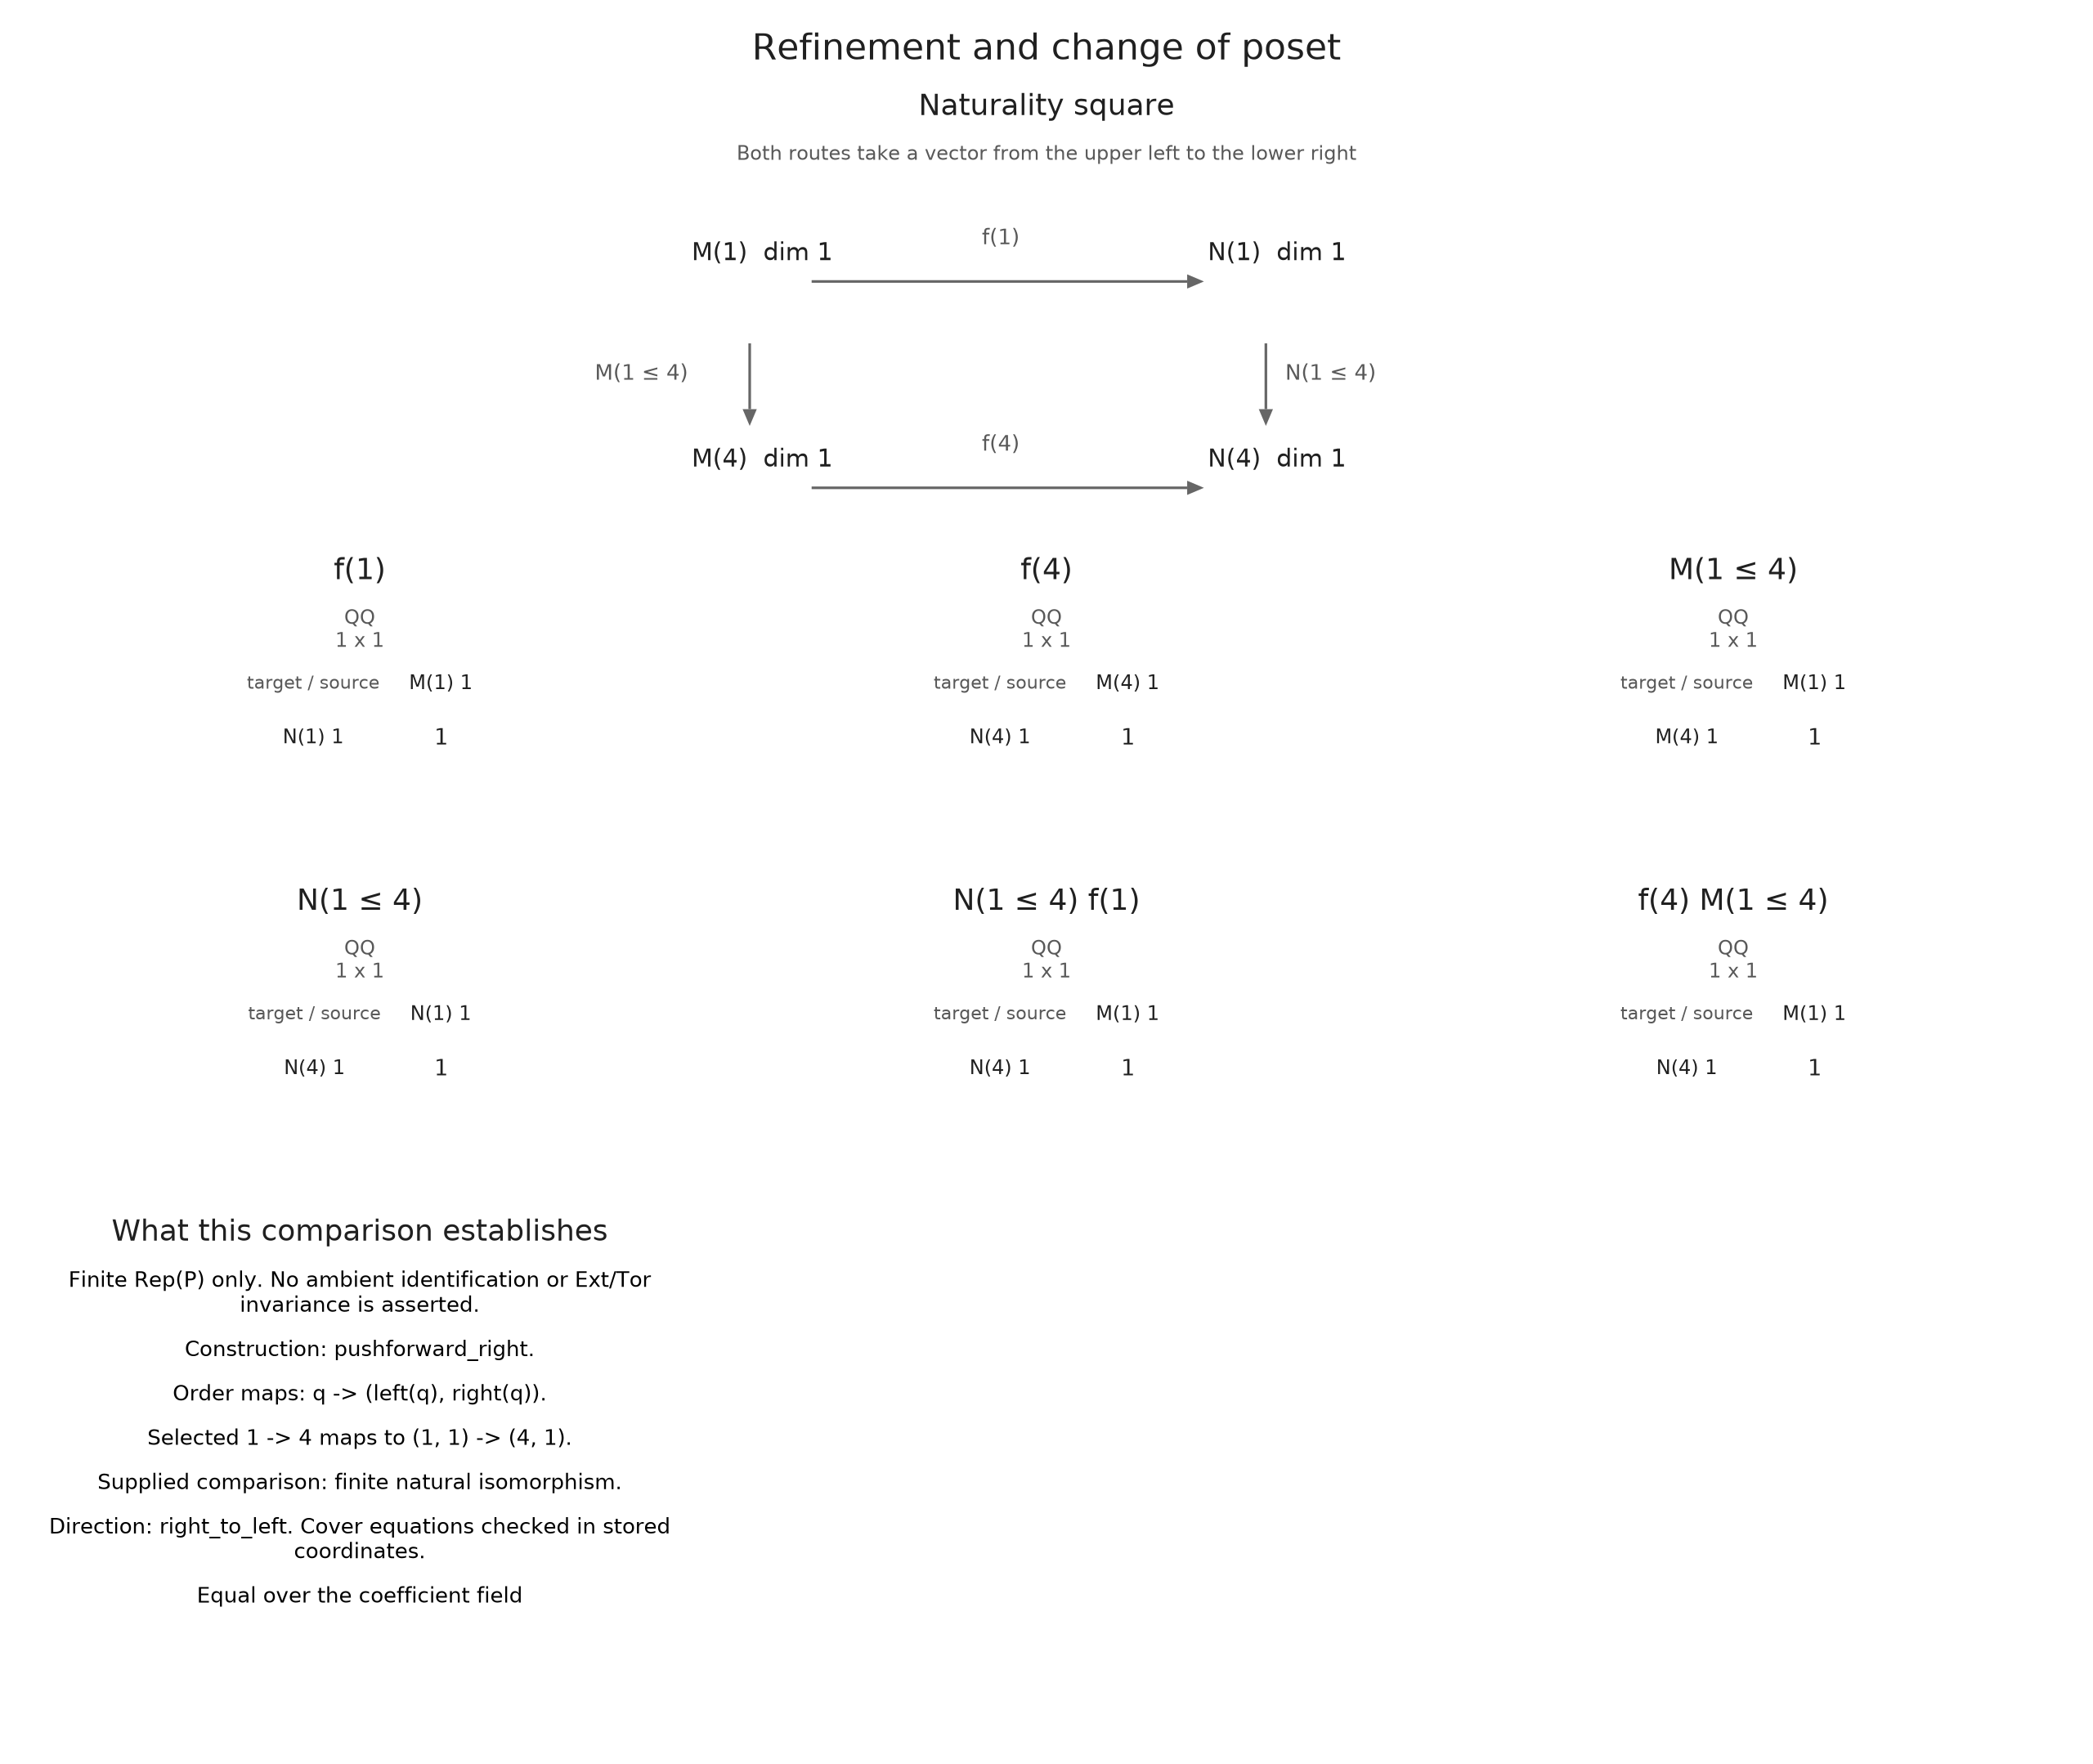

In [12]:
right_transport = OP.pushforward_right(collapse, encoded_C)
counit = OP.Advanced.kan_counit(collapse,C; side=:right)
OP.visualize(right_transport; comparison=counit, direction=:right_to_left, pair=(1,4), view=:square)


## Explore and test a prediction

Which fine labels lie over coarse label 1? Predict them before selecting it. Then change the parameter from $(1/2,1/2)$ to $(3/2,3/2)$: the fine label changes, while the coarse label remains 1.


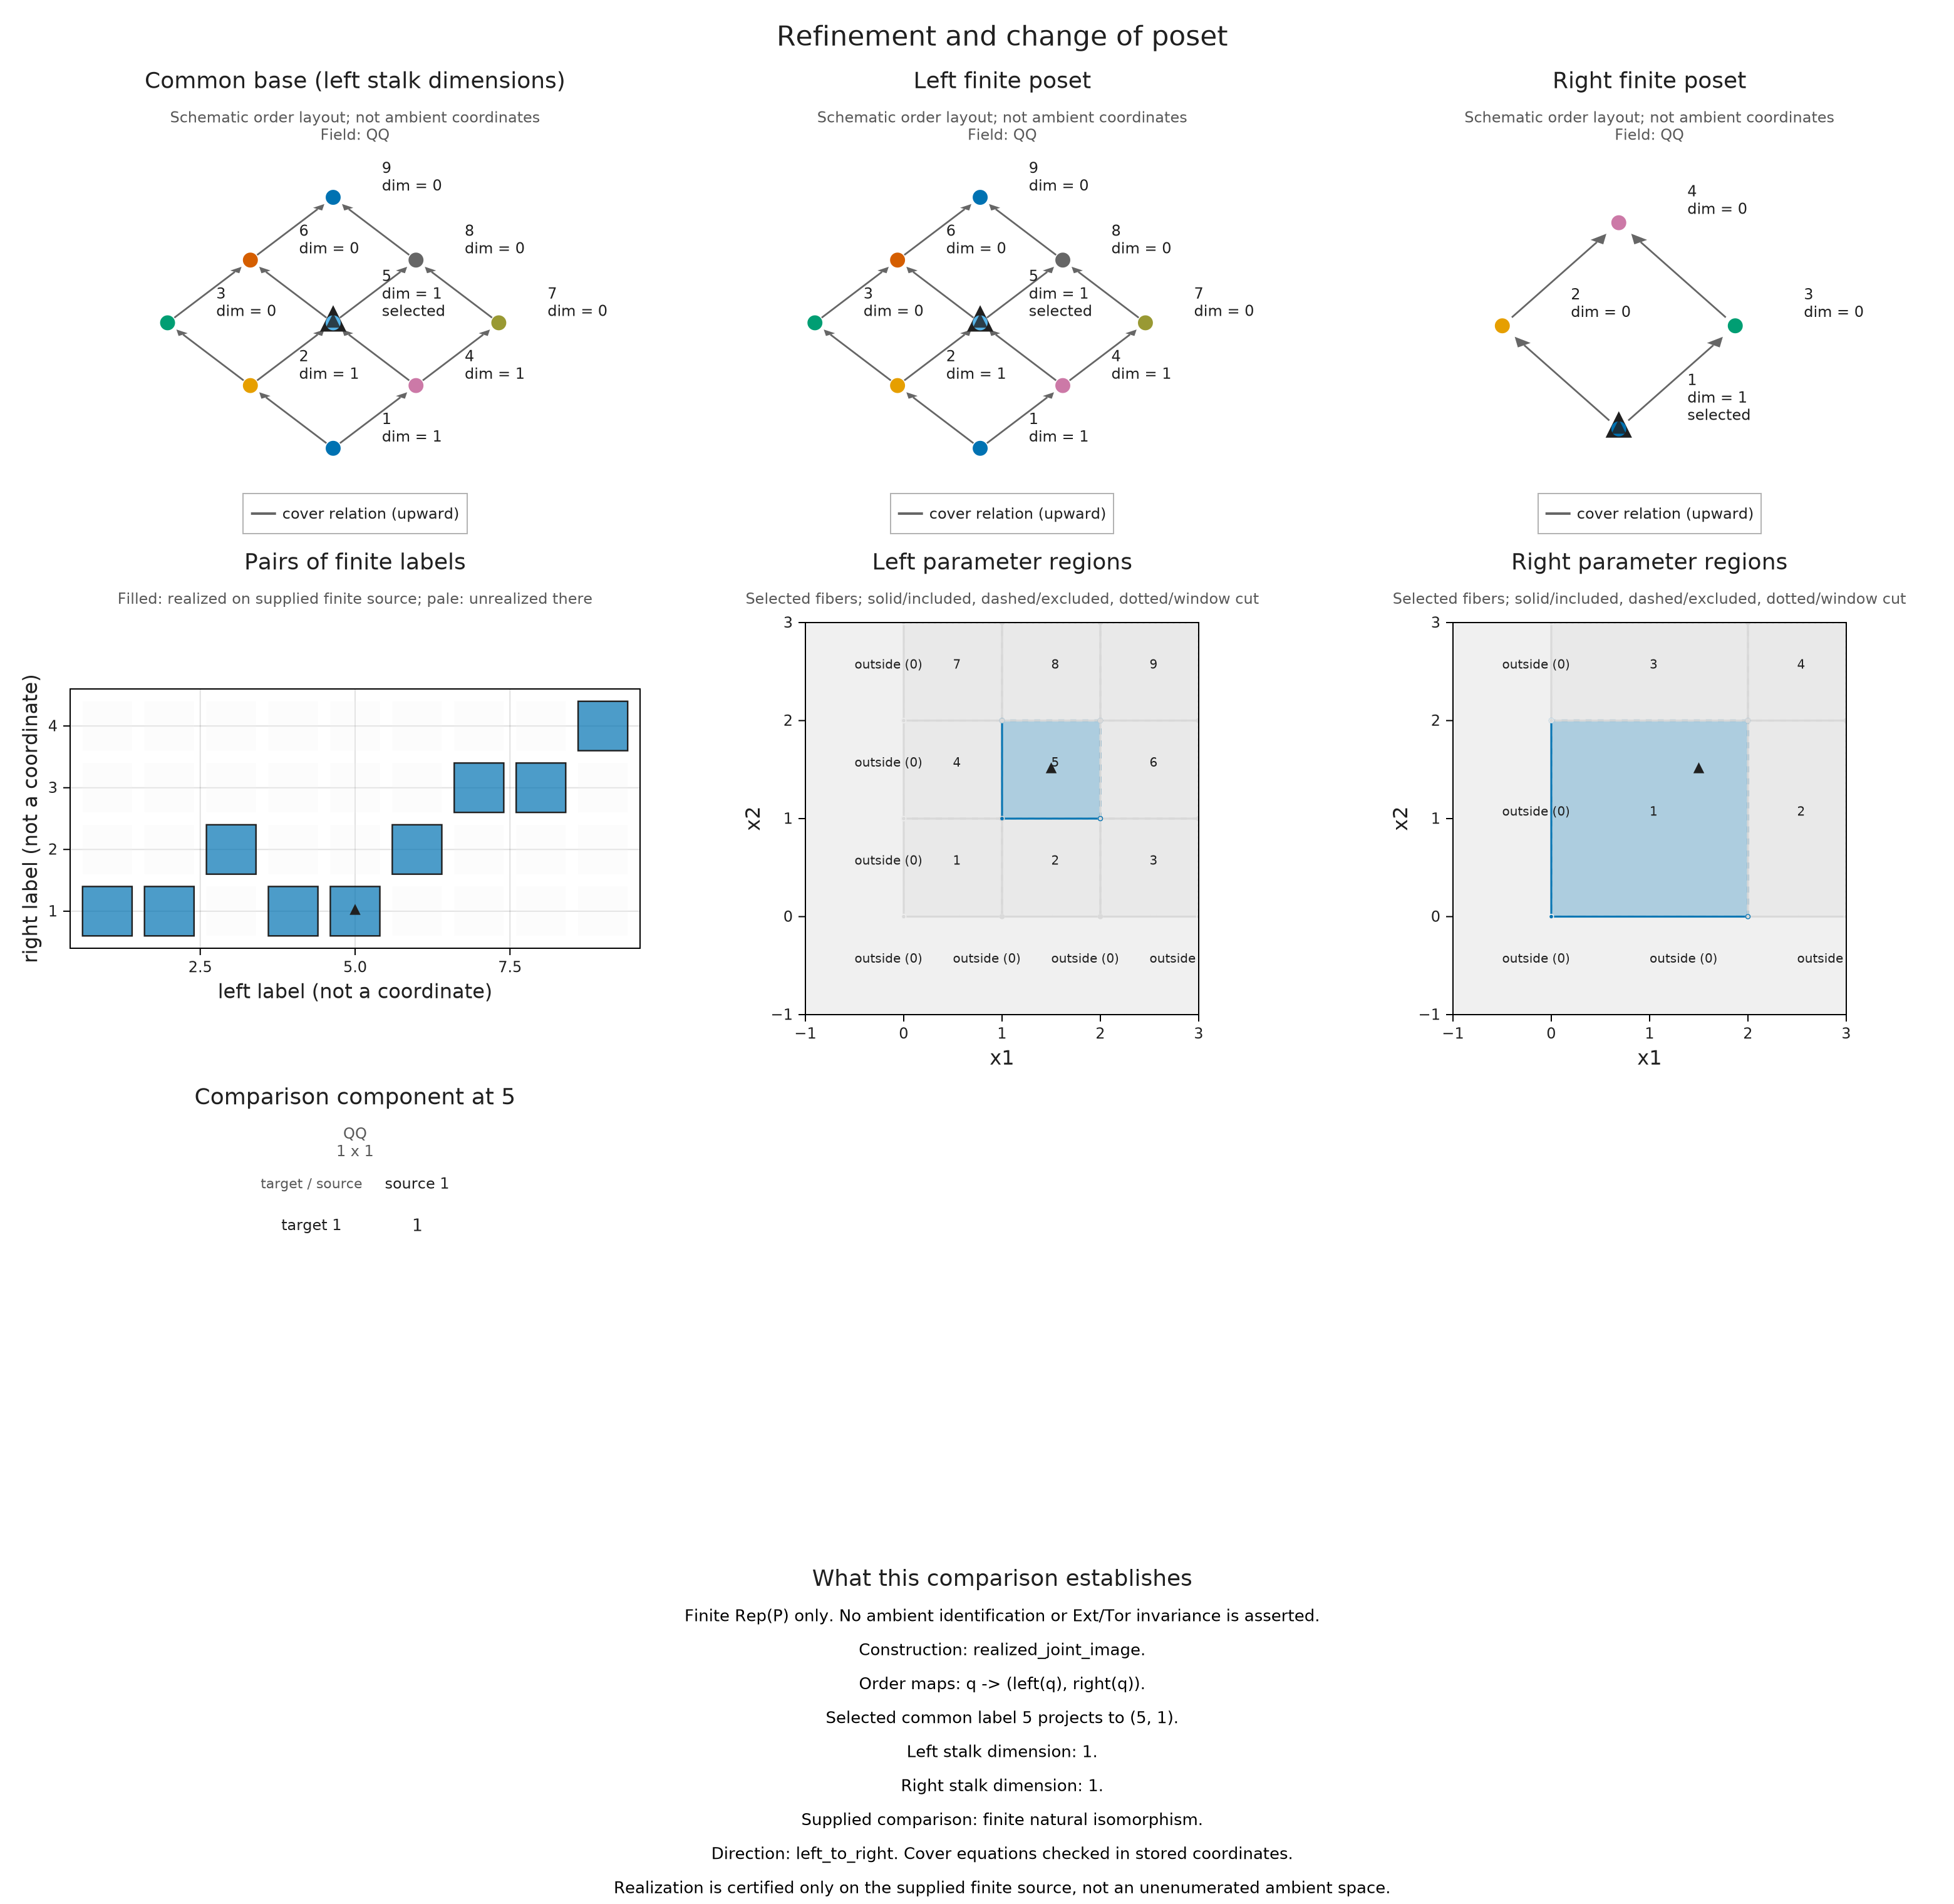

In [13]:
session = OP.inspection_session(refined; sources=(left,right), joint, comparison, box=((-1,-1),(3,3)))
OP.Advanced.select_inspection!(session; side=:right, label=1)
@assert OP.Advanced.inspection_summary(session).candidates == [1,2,4,5]
OP.Advanced.select_inspection!(session; point=(3//2,3//2))
@assert OP.Advanced.inspection_snapshot(session).metadata.selection.query_labels == (5,1)
OP.visualize(OP.Advanced.inspection_snapshot(session))


For a live notebook, explicitly import `WGLMakie` and display `OP.visualize(session; backend=:wglmakie)`. The controls select labels, exact parameter points, and directed common pairs. Click any Hasse vertex to highlight all its preimages. Hover reads retained labels without requesting algebra. Separate viewers share selections; closing a viewer releases its callbacks, and closing the session releases its inputs while retaining its final static snapshot.

Preparation checks modules and cover maps, and materializes supplied lazy encodings. The default `max_vertices=200` refuses oversized finite-poset layouts; `max_pairs=2500` bounds the optional Cartesian background. `matrix_limit` crops displayed entries, not the actual matrices or certificate. Keep the inputs unchanged while the session is open.


In [14]:
OP.Advanced.close_inspection!(session)
@assert OP.Advanced.check_inspection_session(session).valid


As an extension, replace one nonzero component of `comparison` by zero and inspect a cover square. A failure should be visible even though the two modules still have exactly the same dimensions. To compare genuinely different coordinate choices, supply the corresponding change-of-basis matrices, rather than using identity matrices by default.
